# Ширины слоёв по эффективному рангу: ViT-Tiny на CIFAR-10

**Что внутри.** Вопрос: годится ли эффективный ранг (erank) активаций как правило выбора ширины слоёв — простой
поиск архитектуры — по сравнению с равномерным сужением и классическими критериями структурного прунинга.
Здесь это проверяется на ViT-Tiny (12 блоков, скрытый слой MLP 768) с полным рецептом обучения (100 эпох AdamW,
3 сида): erank измеряется по слоям и во время обучения, по нему выбираются ширины скрытых слоёв MLP, сети
обучаются с нуля и дообучаются после среза, процедура повторяется итеративно. Весь код — в этом файле; все числа
в выводах считаются из собственных прогонов.

| Шаг | Что считается | Графики |
|---|---|---|
| 1 | базовая сеть ×3 сида; erank всех 25 слоёв после обучения, во время обучения и без обучения | точность по эпохам; erank по слоям; erank по эпохам |
| 2 | меры размерности, точки замера, вариант «одна картинка»; потребность блока (L1-срез, PCA); Spearman | кривые чувствительности; корреляции мер; erank против потребности |
| 3 | ширины uniform / random / erank / Taylor / L1-потребность при 50% и 40% параметров, обучение с нуля; low-rank fc2 (PCA, SVD) | точность против параметров и MACs; разница с uniform (t95); ширины по блокам |
| 4 | срез обученной сети (L1 / Taylor / случайно) → 10 эпох дообучения против тех же ширин с нуля | до и после дообучения, с нуля; FT − scratch |
| 5 | (a) erank → ширины → обучение с нуля, 3 раунда при 50%; (b) 50% → 40%: срез + дообучение и с нуля | ширины и точность по раундам |
| — | размер, MACs, время инференса CPU / GPU | точность против задержки |
| Итог | разница каждого метода с uniform, парная по сиду (t95, n), и вывод из чисел шагов 2–5 | таблица |

**Полный прогон:** около 5 ч на одной GPU уровня RTX 5070 Ti (≈ 40 обучений по 100 эпох, ~6 мин каждое).
Каждый законченный прогон дописывается в `runs/03_vit.jsonl` (сети — в `runs/ckpt/03_vit/`), ход виден в
`runs/03_vit.log`; повторный запуск продолжает с места остановки, а не обучает заново. Ключ прогона содержит
ширины, сид и число эпох, но не остальные константы (lr, доли чувствительности, размеры подвыборок): после их
изменения удалите `runs/03_vit.jsonl` и `runs/ckpt/03_vit/`.

**Быстрая проверка:** `QUICK = True` в первой ячейке кода — 1 сид, 1 эпоха, 2048 обучающих и 1000 валидационных
картинок, все ячейки и графики за несколько минут; числа в этом режиме смысла не имеют.

**Данные:** CIFAR-10 в формате torchvision (`cifar-10-batches-py/`) в `data/` рядом с файлом или уровнем выше
(`../data/`). Ничего не скачивается (`DOWNLOAD = False`). Валидация — 5000 картинок из обучающей выборки
(фиксированная перестановка), тест используется только для итоговой точности каждой сети.

In [1]:
QUICK = False  # True — быстрая проверка всех ячеек (1 сид, 1 эпоха, подвыборка)
NB_NAME = "03_vit"

import platform

import torch

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DOWNLOAD = False                # True lets torchvision download CIFAR-10 when it is missing
SEEDS = [0, 1, 2]
EPOCHS, LR = 100, 1e-3          # AdamW, one-cycle lr (5% warm-up), gradient clip 1.0, bf16 training forward
FT_EPOCHS, FT_LR = 10, 1e-4     # fine-tuning after a cut
LOWRANK_FT_EPOCHS = FT_EPOCHS // 2
TRAIN_KW = {"optimizer": "adamw", "wd": 0.05}
BUDGETS = [0.5, 0.4]            # fractions of the full network's parameters (8 neurons per block alone: 34.5%)
FLOOR = 8                       # minimum width of fit_budget / global_widths
ALLOC_METHODS = ["uniform", "random", "erank", "taylor_global", "l1_need"]
FT_METHODS, FT_SELECTS = ["uniform", "erank"], ["l1", "taylor", "random"]
LOWRANK_MULTS = [0.5, 1, 2]
ITER_BUDGET, ITER_ROUNDS = 0.5, 3
PROGRESSIVE_BUDGETS = [0.5, 0.4]
SENS_FRACTIONS = [1 / 64, 1 / 32, 1 / 16, 3 / 32, 1 / 8, 3 / 16, 1 / 4, 5 / 16, 3 / 8, 1 / 2, 5 / 8, 3 / 4,
                  13 / 16, 7 / 8, 15 / 16]
SENS_DROP = 1.0                 # need = smallest width whose val accuracy is at most 1 p.p. below the full net
PCA_CALIB = (10_000, 12_000)    # x_train slice for the PCA basis of the sensitivity step
N_PROBE, N_PER_IMAGE, N_TRAIN_ACC = 1000, 500, 5000
LAT_REPEATS, LAT_REPEATS_B1, LAT_THREADS = 30, 100, 4
LAT_GPU_ROUNDS = 3              # GPU time of a net = median over 3 rounds, each timing all nets in turn
N_TRAIN = N_VAL = N_TEST = None  # None = all pictures
if QUICK:
    SEEDS = [0]
    EPOCHS = FT_EPOCHS = LOWRANK_FT_EPOCHS = 1
    N_TRAIN, N_VAL, N_TEST = 2048, 1000, 2000
    SENS_FRACTIONS = [1 / 16, 1 / 2]
    PCA_CALIB = (1024, 2048)
    ITER_ROUNDS = 2
    N_PER_IMAGE, N_TRAIN_ACC = 100, 1000
    LAT_REPEATS = LAT_REPEATS_B1 = 3
PROBE_EPOCHS = [e for e in sorted({1, 2, 3, 5, *range(10, 101, 5)}) if e <= EPOCHS]  # per-epoch erank only here

print(f"torch {torch.__version__}, python {platform.python_version()}, device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "") + (", QUICK" if QUICK else ""))

torch 2.12.1+cu130, python 3.13.13, device cuda (NVIDIA GeForce RTX 5070 Ti)


In [2]:
import matplotlib.pyplot as plt

PALETTE = {
    "uniform": "#52514e",   # reference: dark grey, dashed line
    "random": "#a3a29c",    # light grey
    "erank": "#2a78d6",     # blue
    "taylor": "#eb6834",    # orange   (taylor_global, taylor_cost, Taylor selection)
    "gamma": "#1baf7a",     # aqua     (gamma_global, gamma selection)
    "slimming": "#eda100",  # yellow
    "l1": "#e87ba4",        # magenta  (l1_need, L1 selection)
    "dnas": "#008300",      # green
    "erank_sv": "#6250d6",  # violet   (also erank variants: PR, energy99, pre-activation -> use markers)
    "cost": "#e34948",      # red      (cost_only; erank_cost = blue with a dotted line)
    "hrank": "#6250d6", "variance": "#6250d6", "teacher": "#0b0b0b",
    "pca": "#2a78d6", "svd": "#e34948",
}
MARKERS = {"uniform": "o", "random": "X", "erank": "D", "erank_sv": "v", "taylor": "^", "gamma": "s",
           "slimming": "P", "l1": "p", "dnas": "*", "cost": "h", "erank_cost": "d", "hrank": "<",
           "variance": ">", "teacher": "*", "pca": "o", "svd": "s"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "lines.markersize": 6, "legend.frameon": False,
    "axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb", "axes.edgecolor": "#8a8984",
    "text.color": "#0b0b0b", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e"})
INK, FULL_COLOR, BAR_GREY, NOTE_GREY = "#0b0b0b", "#0b0b0b", "#e4e3de", "#77766f"
# method / selection / basis of this notebook -> (Russian label, palette key)
METHOD = {"uniform": ("uniform (равномерно)", "uniform"), "random": ("случайные ширины", "random"),
          "erank": ("erank", "erank"), "taylor_global": ("Taylor (глобально)", "taylor"),
          "l1_need": ("L1-потребность блока", "l1")}
SELECT = {"l1": ("L1 весов", "l1"), "taylor": ("Taylor", "taylor"), "random": ("случайно", "random")}
BASIS = {"pca": ("PCA активаций", "pca"), "svd": ("SVD весов", "svd")}

## Код

Библиотечные ячейки — функции основной серии, скопированные без изменений (источник указан в первой строке
ячейки); где функция урезана (убраны ветки ResNet и чтение файлов), это отмечено. Новый код помечен «NEW».
Ячейки `cached` / `log` сохраняют каждый законченный прогон, чтобы прерванный ноутбук продолжался с места остановки.

In [3]:
# cache helpers (identical in all notebooks of this set)
import copy
import datetime
import hashlib
import json
import math
import time
from math import sqrt
from pathlib import Path
from statistics import mean, stdev

import numpy as np
import pandas as pd
import torch.nn.functional as F
import re

from IPython.display import Markdown as _IPyMarkdown, display
from torch import Tensor, nn

_RU_DECIMAL = re.compile(r"(?<=\d)\.(?=\d)")
_RU_MINUS = re.compile(r"(?<![\w)\]])-(?=\d)")


def Markdown(text: str):
    """IPython Markdown in the number style of the Russian text: decimal comma and a true minus sign (0,59; −0,40)."""
    return _IPyMarkdown(_RU_MINUS.sub("−", _RU_DECIMAL.sub(",", text)))

RUNS = Path("runs")
RESULTS = RUNS / (f"{NB_NAME}_quick.jsonl" if QUICK else f"{NB_NAME}.jsonl")
CKPT = RUNS / (f"{NB_NAME}_quick_ckpt" if QUICK else f"ckpt/{NB_NAME}")
LOG = RUNS / (f"{NB_NAME}_quick.log" if QUICK else f"{NB_NAME}.log")
_ROWS = None  # run_id -> row, read once from RESULTS


def log(msg: str) -> None:
    """Print, and append a timestamped line to LOG (a long unattended run can be followed there)."""
    line = f"{datetime.datetime.now():%Y-%m-%d %H:%M:%S}  {msg}"
    print(line, flush=True)
    LOG.parent.mkdir(parents=True, exist_ok=True)
    with LOG.open("a", encoding="utf-8") as f:
        f.write(line + "\n")


def stored_rows() -> dict:
    global _ROWS
    if _ROWS is None:
        _ROWS = {}
        if RESULTS.exists():
            for line in RESULTS.read_text(encoding="utf-8").splitlines():
                try:
                    row = json.loads(line)
                except json.JSONDecodeError:  # empty line, or a run killed while writing
                    continue
                _ROWS[row["run_id"]] = row
    return _ROWS


def partial_tail(path: Path) -> bool:
    """True if the file ends inside a line (a run killed while writing it)."""
    if not path.exists() or path.stat().st_size == 0:
        return False
    with path.open("rb") as f:
        f.seek(-1, 2)
        return f.read(1) != b"\n"


def cached(run_id: str, fn):
    """The stored row of run_id; otherwise row = fn() is appended to RESULTS (one JSON line) and returned.
    A restarted notebook therefore resumes instead of retraining."""
    rows = stored_rows()
    if run_id not in rows:
        t0 = time.time()
        row = {"run_id": run_id, **fn()}
        row.setdefault("seconds", round(time.time() - t0, 1))
        RESULTS.parent.mkdir(parents=True, exist_ok=True)
        lead = "\n" if partial_tail(RESULTS) else ""  # never glue a new row onto a partial line
        with RESULTS.open("a", encoding="utf-8") as f:
            f.write(lead + json.dumps(row, ensure_ascii=False) + "\n")
            f.flush()
        rows[run_id] = row
        log(f"done {run_id}  ({row['seconds']} s)")
    return rows[run_id]


def ckpt_path(run_id: str) -> Path:
    """Checkpoint (state_dict) of a run, named by a hash of its run_id."""
    return CKPT / f"{hashlib.md5(run_id.encode()).hexdigest()[:16]}.pt"

In [4]:
# src/erank_nas/spectrum.py (verbatim): erank and the other spectral measures

def _entropy_rank(weights: Tensor) -> float:
    """exp(entropy of the normalized weights). If k weights are equal and the rest are 0, this gives exactly
    k, so it reads as "how many directions really matter"; an uneven spread gives a number between 1 and k."""
    weights = weights.double().clamp_min(0)
    total = weights.sum()
    if total <= 0:
        return 0.0
    p = weights / total
    p = p[p > 0]
    return math.exp(float(-(p * p.log()).sum()))


def erank_sv(eigvals: Tensor) -> float:
    """Entropy effective rank, distribution built from singular values sigma = sqrt(lambda)."""
    return _entropy_rank(eigvals.double().clamp_min(0).sqrt())


def erank_energy(eigvals: Tensor) -> float:
    """Entropy effective rank with distribution built from lambda (= sigma^2)."""
    return _entropy_rank(eigvals)


def participation_ratio(eigvals: Tensor) -> float:
    ev = eigvals.double().clamp_min(0)
    denom = float((ev**2).sum())
    return float(ev.sum()) ** 2 / denom if denom > 0 else 0.0


def stable_rank(eigvals: Tensor) -> float:
    ev = eigvals.double().clamp_min(0)
    top = float(ev.max()) if ev.numel() else 0.0
    return float(ev.sum()) / top if top > 0 else 0.0


def energy_rank(eigvals: Tensor, threshold: float = 0.99) -> int:
    ev = eigvals.double().clamp_min(0).sort(descending=True).values
    total = float(ev.sum())
    if total <= 0:
        return 0
    cum = torch.cumsum(ev, 0) / total
    return int((cum < threshold - 1e-12).sum().item()) + 1  # -1e-12: round-off must not hide a share exactly at the threshold


def numerical_rank(eigvals: Tensor, rtol: float = 1e-6) -> int:
    sv = eigvals.double().clamp_min(0).sqrt()
    if sv.numel() == 0 or float(sv.max()) == 0:
        return 0
    return int((sv > rtol * sv.max()).sum().item())


def all_metrics(eigvals: Tensor) -> dict[str, float]:
    return {
        "erank_sv": erank_sv(eigvals),
        "erank_energy": erank_energy(eigvals),
        "participation_ratio": participation_ratio(eigvals),
        "stable_rank": stable_rank(eigvals),
        "energy90": float(energy_rank(eigvals, 0.90)),
        "energy99": float(energy_rank(eigvals, 0.99)),
        "rank": float(numerical_rank(eigvals)),
        "dim": float(eigvals.numel()),
    }

In [5]:
# vit/model.py (verbatim): ViT-Tiny for 32x32 pictures, patch 4 -> 64 tokens, no CLS token

DIM, DEPTH, HEADS, HIDDEN, PATCH = 192, 12, 3, 768, 4


class Block(nn.Module):
    def __init__(self, dim: int, heads: int, hidden: int):
        super().__init__()
        self.heads = heads
        self.norm1 = nn.LayerNorm(dim)
        self.qkv = nn.Linear(dim, 3 * dim)  # queries, keys and values of all heads at once
        self.proj = nn.Linear(dim, dim)
        self.norm2 = nn.LayerNorm(dim)
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)

    def forward(self, x: torch.Tensor, acts: list | None = None) -> torch.Tensor:
        b, t, d = x.shape  # (batch, tokens, dim)
        q, k, v = self.qkv(self.norm1(x)).view(b, t, 3, self.heads, d // self.heads).permute(2, 0, 3, 1, 4)
        x = x + self.proj(F.scaled_dot_product_attention(q, k, v).transpose(1, 2).reshape(b, t, d))
        inner = F.gelu(self.fc1(self.norm2(x)))  # (batch, tokens, hidden)
        x = x + self.fc2(inner)
        if acts is not None:
            acts += [inner, x]
        return x


class ViT(nn.Module):
    def __init__(self, inner_widths: list[int] | None = None, num_classes: int = 10):
        """inner_widths: the MLP hidden width of every block (default 768 each)."""
        super().__init__()
        self.tokens = (32 // PATCH) ** 2
        self.embed = nn.Conv2d(3, DIM, PATCH, PATCH)  # every 4x4x3 patch -> 192 numbers
        self.pos = nn.Parameter(torch.zeros(1, self.tokens, DIM))  # learned position of every token
        self.blocks = nn.ModuleList(Block(DIM, HEADS, w) for w in (inner_widths or [HIDDEN] * DEPTH))
        self.norm = nn.LayerNorm(DIM)
        self.head = nn.Linear(DIM, num_classes)
        nn.init.trunc_normal_(self.pos, std=0.02)
        for m in self.modules():
            if isinstance(m, nn.Linear):  # the usual ViT initialization
                nn.init.trunc_normal_(m.weight, std=0.02)
                nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor, acts: list | None = None) -> torch.Tensor:
        """x: (batch, 3, 32, 32). If a list `acts` is given, every hidden activation is appended to it, in the
        order of layer_names(): (batch, tokens, width) tensors."""
        x = self.embed(x).flatten(2).transpose(1, 2) + self.pos  # (batch, 64, 192)
        if acts is not None:
            acts.append(x)
        for block in self.blocks:
            x = block(x, acts)
        return self.head(self.norm(x).mean(1))  # average over the 64 tokens

    def layer_names(self) -> list[tuple[str, int]]:
        names = [("embed", DIM)]
        for i, block in enumerate(self.blocks, 1):
            names += [(f"block {i} inner", block.fc1.out_features), (f"block {i} out", DIM)]
        return names

    def inner_widths(self) -> list[int]:
        return [block.fc1.out_features for block in self.blocks]

    def neuron_cost(self, measure: str = "params") -> list[int]:
        """What ONE hidden neuron of each block costs: its row of fc1 (+ bias) and its column of fc2; in
        multiply-adds, both applied to every token."""
        if measure == "params":
            return [2 * DIM + 1] * len(self.blocks)
        return [2 * DIM * self.tokens] * len(self.blocks)

    def attention_macs(self) -> int:
        """Multiply-adds of the attention products (queries x keys, weights x values), which are not modules."""
        return len(self.blocks) * 2 * self.tokens * self.tokens * DIM

In [6]:
# resnet/data.py (verbatim): CIFAR as tensors, the 45k / 5k split, augmentation

MEAN = {"cifar10": (0.4914, 0.4822, 0.4465), "cifar100": (0.5071, 0.4865, 0.4409)}


STD = {"cifar10": (0.2470, 0.2435, 0.2616), "cifar100": (0.2673, 0.2564, 0.2762)}


def load_cifar10(root: str = "data", device: str = "cpu", val_size: int = 5000, name: str = "cifar10") -> dict:
    """Pictures as (N, 3, 32, 32) tensors, standardized per colour channel. name="cifar100": the same for
    CIFAR-100 (the same pictures size, 100 classes; root must contain cifar-100-python/).

    The validation split is cut from the official train set with a fixed seed (the same images every run);
    the official test set is kept for the final number only. Nothing is downloaded.
    """
    from torchvision import datasets  # imported here so the rest of the package works without torchvision

    mean, std = torch.tensor(MEAN[name]).view(1, 3, 1, 1), torch.tensor(STD[name]).view(1, 3, 1, 1)
    dataset = datasets.CIFAR100 if name == "cifar100" else datasets.CIFAR10

    def to_tensors(ds):
        x = torch.as_tensor(ds.data).permute(0, 3, 1, 2).float() / 255  # stored as (N, 32, 32, 3) uint8
        return (x - mean) / std, torch.as_tensor(ds.targets)

    (x_all, y_all) = to_tensors(dataset(root, train=True))
    (x_test, y_test) = to_tensors(dataset(root, train=False))
    order = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(0))
    val_idx, train_idx = order[:val_size], order[val_size:]
    split = {
        "x_train": x_all[train_idx], "y_train": y_all[train_idx],
        "x_val": x_all[val_idx], "y_val": y_all[val_idx],
        "x_test": x_test, "y_test": y_test,
    }
    return {k: v.to(device) for k, v in split.items()}


def augment(x: torch.Tensor) -> torch.Tensor:
    """x: (batch, 3, 32, 32). Every picture gets its own random shift (up to 4 pixels) and a coin-flip mirror."""
    padded = F.pad(x, (4, 4, 4, 4))  # (batch, 3, 40, 40); padding with 0 = the average colour after standardizing
    out = torch.empty_like(x)
    shifts = torch.randint(0, 9, (len(x), 2)).tolist()
    for i, (dy, dx) in enumerate(shifts):
        out[i] = padded[i, :, dy:dy + 32, dx:dx + 32]
    flip = torch.rand(len(x), device=x.device) < 0.5
    out[flip] = out[flip].flip(3)  # dim 3 = width: mirror left-right
    return out

In [7]:
# resnet/train.py (verbatim): evaluation (fp32) and training (here: AdamW branch, bf16 forward)

@torch.no_grad()
def evaluate(model, x: torch.Tensor, y: torch.Tensor, batch_size: int = 1000) -> dict:
    model.eval()  # BatchNorm uses its running statistics, exactly like at inference time
    total_loss, correct = 0.0, 0
    for start in range(0, len(x), batch_size):
        out = model(x[start:start + batch_size])
        target = y[start:start + batch_size]
        total_loss += F.cross_entropy(out, target).item() * len(target)
        correct += (out.argmax(1) == target).sum().item()
    return {"loss": total_loss / len(x), "acc": correct / len(x)}


def train(model, data: dict, epochs: int = 40, lr: float = 0.2, wd: float = 5e-4, batch_size: int = 256,
          seed: int = 0, verbose: bool = True, after_epoch=None, l1_gamma: float = 0.0,
          optimizer: str = "sgd") -> list[dict]:
    """Train on data["x_train"] (with augmentation), report on data["x_val"] after every epoch.
    after_epoch (optional): a function model -> dict, its result is added to that epoch's row (e.g. erank).
    l1_gamma: Network Slimming: + l1_gamma * sum |gamma| of the inner BatchNorm of every block,
    which pushes the gammas of unneeded inner channels to zero.
    optimizer="adamw" (for the ViT, which SGD trains badly): AdamW, 5% of the steps warm-up, gradients clipped
    to norm 1."""
    torch.manual_seed(seed)
    x, y = data["x_train"], data["y_train"]
    steps = epochs * math.ceil(len(x) / batch_size)
    if optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.05,
                                                    cycle_momentum=False)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
        # OneCycleLR also cycles the momentum (0.95 -> 0.85 -> 0.95, opposite to the lr): momentum=0.9 is overwritten
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    history = []
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        order = torch.randperm(len(x), device=x.device)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            with torch.autocast(x.device.type, dtype=torch.bfloat16, enabled=x.is_cuda):
                loss = F.cross_entropy(model(augment(x[idx])), y[idx])
            if l1_gamma:
                loss = loss + l1_gamma * sum(b.bn1.weight.abs().sum() for b in model.blocks)
            opt.zero_grad()
            loss.backward()
            if optimizer == "adamw":
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()  # one-cycle changes the learning rate after every batch, not every epoch

        row = {"epoch": epoch + 1, "seconds": round(time.time() - t0, 2)}
        row.update({f"val_{k}": v for k, v in evaluate(model, data["x_val"], data["y_val"]).items()})
        if after_epoch is not None:
            row.update(after_epoch(model))
        history.append(row)
        if verbose:
            print(f"  epoch {epoch + 1:3d}  val_loss={row['val_loss']:.4f}  val_acc={row['val_acc']:.4f}"
                  f"  ({row['seconds']} s)", flush=True)
    return history

In [8]:
# resnet/measure.py (verbatim): covariance of every layer (a token = one sample), erank per layer

@torch.no_grad()
def channel_covariances(model, x: torch.Tensor, batch_size: int = 500, modules=None) -> list[torch.Tensor]:
    """Covariance between the channels of every layer, (channels, channels) each, in float64.
    modules (optional): measure the outputs of these modules instead (e.g. conv1 of every block, before its
    BatchNorm), in the order they run."""
    model.eval()  # BatchNorm uses running statistics, as at inference time
    sums, outer, count = None, None, None
    for start in range(0, len(x), batch_size):
        acts = []
        if modules is None:
            model(x[start:start + batch_size], acts)
        else:
            hooks = [m.register_forward_hook(lambda module, inputs, output: acts.append(output)) for m in modules]
            model(x[start:start + batch_size])
            for h in hooks:
                h.remove()
        if sums is None:
            sums = [0.0] * len(acts)
            outer = [0.0] * len(acts)
            count = [0] * len(acts)
        for l, a in enumerate(acts):
            if a.dim() == 3:  # ViT: (pictures, tokens, neurons) -> (pictures * tokens, neurons)
                rows = a.reshape(-1, a.shape[2]).double()
            else:
                rows = a.permute(0, 2, 3, 1).reshape(-1, a.shape[1]).double()  # (pictures * H * W, channels)
            sums[l] = sums[l] + rows.sum(0)
            outer[l] = outer[l] + rows.T @ rows
            count[l] += len(rows)
    covs = []
    for s, o, n in zip(sums, outer, count):
        mean = s / n
        covs.append((o - n * torch.outer(mean, mean)) / (n - 1))  # = sum of (row - mean)(row - mean)^T / (n - 1)
    return covs


def eigvals_desc(cov: torch.Tensor) -> torch.Tensor:
    """Eigenvalues of a covariance matrix, largest first, tiny negative round-off clipped to 0."""
    return torch.linalg.eigvalsh(cov).clamp(min=0).flip(0).cpu()


def layer_metrics(model, x: torch.Tensor) -> list[dict]:
    """One dict per layer: name, width (channels), erank_energy, participation_ratio and the other measures."""
    result = []
    for (name, width), cov in zip(model.layer_names(), channel_covariances(model, x)):
        result.append({"layer": name, "width": width, **all_metrics(eigvals_desc(cov))})
    return result


# NEW (not in the main series): the per-image variant of arXiv 2607.19315
@torch.no_grad()
def per_image_erank(model, x: torch.Tensor, batch_size: int = 50) -> list[float]:
    """erank_energy of the covariance of ONE picture's 64 tokens in the hidden layer of every block, averaged over
    the pictures x. The centered tokens' covariance (hidden x hidden) and Gram matrix (64 x 64) have the same
    non-zero eigenvalues, so the small matrix is used; the value is at most 63."""
    model.eval()
    totals = None
    for start in range(0, len(x), batch_size):
        acts = []
        model(x[start:start + batch_size], acts)
        sums = []
        for a in acts[1::2]:  # (pictures, tokens, hidden)
            a = a.double()
            a = a - a.mean(1, keepdim=True)
            eig = torch.linalg.eigvalsh(a @ a.transpose(1, 2)).clamp(min=0).flip(1).cpu()  # (pictures, tokens)
            sums.append(sum(erank_energy(e) for e in eig))
        totals = sums if totals is None else [t + s for t, s in zip(totals, sums)]
    return [t / len(x) for t in totals]

In [9]:
# resnet/shrink.py: size and HOW MANY neurons per block (verbatim; inner_cost trimmed to the ViT branch)

def count_params(model) -> int:
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def count_macs(model) -> int:
    """Multiply-adds for one 32x32 picture, counted with forward hooks (works for any conv / linear layout)."""
    macs = 0

    def hook(module, inputs, output):
        nonlocal macs
        if isinstance(module, nn.Conv2d):  # every output number costs (input channels x kernel area) multiply-adds
            macs += output.numel() * module.in_channels // module.groups * module.kernel_size[0] * module.kernel_size[1]
        else:  # every output number costs in_features multiply-adds (a ViT applies a Linear to every token)
            macs += output.numel() * module.in_features

    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    model(torch.zeros(1, 3, 32, 32, device=next(model.parameters()).device))
    for h in handles:
        h.remove()
    if hasattr(model, "attention_macs"):  # ViT: the products inside attention are not Conv2d / Linear modules
        macs += model.attention_macs()
    return macs


def inner_cost(model, measure: str = "params") -> list[int]:
    """What ONE inner unit of each block costs. A model that knows the price of its own units (the ViT: one MLP
    neuron, see ViT.neuron_cost) is asked directly. [trimmed: the ResNet branch is dropped]"""
    return model.neuron_cost(measure)


def size_fn(base, measure: str = "params"):
    """A function widths -> size of `base` with these inner widths (everything else unchanged).
    The size is linear in the inner widths: a fixed part plus cost x width for every block."""
    cost = inner_cost(base, measure)
    full = count_params(base) if measure == "params" else count_macs(base)
    fixed = full - sum(c * w for c, w in zip(cost, base.inner_widths()))
    return lambda widths: fixed + sum(c * w for c, w in zip(cost, widths))


def fit_budget(shares: list[float], budget: int, base, floor: int = 8, measure: str = "params") -> list[int]:
    """Inner widths proportional to `shares` (erank, the original widths, ...), no wider than the original and
    no narrower than `floor`. The common scale grows by 1% while the network still fits into `budget`
    (parameters or multiply-adds, see `measure`)."""
    max_widths = base.inner_widths()
    size = size_fn(base, measure)

    def widths(scale):
        return [min(m, max(floor, round(scale * s))) for s, m in zip(shares, max_widths)]

    scale = 1e-3
    while size(widths(scale * 1.01)) <= budget and widths(scale * 1.01) != max_widths:
        scale *= 1.01
    assert size(widths(scale)) <= budget, "budget below the network with `floor` channels in every block"
    return widths(scale)


def global_widths(scores: list[torch.Tensor], budget: int, base, floor: int = 8, measure: str = "params") -> list[int]:
    """Reserve the best `floor` channels of every block, then add remaining channels best-first while they fit.
    The reserved channels must not buy extra width a second time. The result specifies widths, not indices."""
    cost = inner_cost(base, measure)
    widths = [min(floor, len(s)) for s in scores]
    used = size_fn(base, measure)(widths)
    if used > budget:
        raise ValueError("budget below the network with the minimum width in every block")
    ranked = sorted(((float(s), b) for b, block_scores in enumerate(scores)
                     for s in block_scores.sort(descending=True).values[widths[b]:]), reverse=True)
    for _, b in ranked:
        if widths[b] < len(scores[b]) and used + cost[b] <= budget:
            widths[b] += 1
            used += cost[b]
    return widths


def top_k(scores: torch.Tensor, k: int) -> torch.Tensor:
    return scores.argsort(descending=True)[:k]

In [10]:
# vit/shrink.py (verbatim): WHICH neurons (L1 / Taylor / random), cutting them, low-rank fc2

def neuron_scores(model, method: str, seed: int = 0, data: dict | None = None) -> list[torch.Tensor]:
    """One importance score per hidden neuron of every block (bigger = more important)."""
    if method == "l1":  # filter pruning for a Linear layer: L1 norm of the neuron's weights in fc1
        return [b.fc1.weight.detach().abs().sum(1).cpu() for b in model.blocks]
    if method == "taylor":
        return taylor_scores(model, data, seed)
    if method == "random":
        g = torch.Generator().manual_seed(seed)
        return [torch.rand(b.fc1.out_features, generator=g) for b in model.blocks]
    raise ValueError(f"{method!r} does not apply to the ViT (no BatchNorm gammas, no per-neuron 2D maps)")


def taylor_scores(model, data: dict, seed: int = 0, n_batches: int = 20, batch_size: int = 256) -> list[torch.Tensor]:
    """First-order Taylor importance without BatchNorm: put a gate g = 1 on every hidden neuron; the loss change if the
    neuron were removed is ~ (dL/dg)^2, and dL/dg = sum over tokens of activation x dL/dactivation."""
    model.eval()
    torch.manual_seed(seed)
    totals = [torch.zeros(b.fc1.out_features) for b in model.blocks]
    x, y = data["x_train"], data["y_train"]
    for _ in range(n_batches):
        idx = torch.randint(len(x), (batch_size,), device=x.device)
        acts = []
        loss = nn.functional.cross_entropy(model(x[idx], acts), y[idx])
        hidden = acts[1::2]  # acts = [embed, inner 1, out 1, inner 2, ...]
        grads = torch.autograd.grad(loss, hidden)
        for total, h, g in zip(totals, hidden, grads):
            total += (h * g).sum((0, 1)).detach().cpu() ** 2
    return [t / n_batches for t in totals]


@torch.no_grad()
def keep_inner(model, keep: list[torch.Tensor]):
    """A copy of `model` that keeps only the hidden neurons keep[b] of every block, with their weights."""
    small = copy.deepcopy(model)
    for block, idx in zip(small.blocks, keep):
        idx = idx.sort().values.to(block.fc1.weight.device)
        fc1 = nn.Linear(block.fc1.in_features, len(idx))
        fc1.weight.copy_(block.fc1.weight[idx])
        fc1.bias.copy_(block.fc1.bias[idx])
        fc2 = nn.Linear(len(idx), block.fc2.out_features)
        fc2.weight.copy_(block.fc2.weight[:, idx])
        fc2.bias.copy_(block.fc2.bias)
        block.fc1, block.fc2 = fc1, fc2
    return small.to(next(model.parameters()).device).train(model.training)


@torch.no_grad()
def lowrank_fc2(model, ranks: list[int], basis: str, blocks: list[int] | None, covs, means):
    """Keep every hidden neuron, but let fc2 of block b read only ranks[b] combinations of them:
    fc2 (hidden -> 192) becomes Linear (hidden -> r) followed by Linear (r -> 192); a rank too high to save
    parameters (r >= hidden * 192 / (hidden + 192), 153 for the full MLP) leaves fc2 as it is.
    basis="pca": the top-r principal directions of the hidden ACTIVATIONS (what erank counts); the mean goes
                 into the bias. basis="svd": the top-r singular directions of the WEIGHTS of fc2.
    covs / means: channel_covariances / inner_means of `model` (needed for "pca")."""
    small = copy.deepcopy(model)
    for b, (block, r) in enumerate(zip(small.blocks, ranks)):
        if blocks is not None and b not in blocks:
            continue
        W, bias = block.fc2.weight.double(), block.fc2.bias.double()  # (192, hidden)
        if r * sum(W.shape) >= W.numel():  # two layers of rank r would not be smaller than fc2: keep it (as in MLP)
            continue
        first = nn.Linear(W.shape[1], r, bias=False)
        second = nn.Linear(r, W.shape[0])
        if basis == "pca":
            V = torch.linalg.eigh(covs[2 * b + 1]).eigenvectors.flip(1)[:, :r].to(W.device)  # (hidden, r), top first
            mu = means[b].to(W.device)
            first.weight.copy_(V.T.float())
            second.weight.copy_((W @ V).float())
            # h = mu + V V^T (h - mu) + small rest, so W h ~ W V (V^T h) + W (mu - V V^T mu)
            second.bias.copy_((bias + W @ (mu - V @ (V.T @ mu))).float())
        else:
            U, S, Vh = torch.linalg.svd(W, full_matrices=False)
            first.weight.copy_((S[:r, None].sqrt() * Vh[:r]).float())
            second.weight.copy_((U[:, :r] * S[:r].sqrt()).float())
            second.bias.copy_(bias.float())
        block.fc2 = nn.Sequential(first, second).to(W.device)
    return small.train(model.training)


@torch.no_grad()
def inner_means(model, x: torch.Tensor, batch_size: int = 500) -> list[torch.Tensor]:
    """Average value of every hidden neuron (over pictures and tokens), float64."""
    model.eval()
    sums, count = None, 0
    for start in range(0, len(x), batch_size):
        acts = []
        model(x[start:start + batch_size], acts)
        batch_sums = [a.double().sum((0, 1)) for a in acts[1::2]]
        sums = batch_sums if sums is None else [s + t for s, t in zip(sums, batch_sums)]
        count += acts[0].shape[0] * acts[0].shape[1]
    return [s / count for s in sums]

In [11]:
# resnet/experiments.py: helpers (verbatim) and alloc_widths (trimmed to the ViT methods)

def inner(metrics: list[dict], key: str) -> list[float]:
    """The value of `key` for the inner layer of every block (metrics come in layer_names() order)."""
    return [m[key] for m in metrics if m["layer"].endswith("inner")]


def describe(model) -> dict:
    return {"params": count_params(model), "macs": count_macs(model), "inner_widths": model.inner_widths()}


@torch.no_grad()
def latency_ms(model, device: str, batch: int, repeats: int = 30) -> float:
    model.eval()
    x = torch.randn(batch, 3, 32, 32, device=device)
    with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
        for _ in range(5):  # warm-up
            model(x)
        if device == "cuda":
            torch.cuda.synchronize()
        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            model(x)
            if device == "cuda":
                torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
    return 1000 * sorted(times)[len(times) // 2]  # median, in milliseconds


def alloc_widths(method: str, base, metrics: list[dict], budget: int, seed: int, data: dict | None = None,
                 measure: str = "params", need: list[int] | None = None) -> list[int]:
    """Inner widths proposed by `method` for a budget of `budget` parameters (or multiply-adds).
    [trimmed: the ViT methods of resnet/experiments.py; "l1_need" is "need" there, with the need passed in]"""
    if method == "uniform":
        return fit_budget(base.inner_widths(), budget, base, measure=measure)
    if method == "random":  # random share of the original width, between 20% and 100%
        g = torch.Generator().manual_seed(seed)
        shares = [w * (0.2 + 0.8 * float(torch.rand(1, generator=g))) for w in base.inner_widths()]
        return fit_budget(shares, budget, base, measure=measure)
    if method == "erank":
        return fit_budget(inner(metrics, "erank_energy"), budget, base, measure=measure)
    if method == "erank_sv":
        return fit_budget(inner(metrics, "erank_sv"), budget, base, measure=measure)
    if method == "participation_ratio":
        return fit_budget(inner(metrics, "participation_ratio"), budget, base, measure=measure)
    if method == "taylor_global":
        return global_widths(neuron_scores(base, "taylor", seed, data), budget, base, measure=measure)
    if method == "l1_need":  # reference: widths proportional to what each block alone needs (step 2, L1 cut)
        return fit_budget(need, budget, base, measure=measure)
    raise ValueError(method)

In [12]:
# src/erank_nas/uncertainty.py and resnet/plots.py analysis helpers (verbatim unless marked)

T975 = (
    None, 12.7062047364, 4.3026527299, 3.1824463053, 2.7764451052,
    2.5705818356, 2.4469118511, 2.3646242516, 2.3060041352, 2.2621571629,
    2.2281388520, 2.2009851601, 2.1788128297, 2.1603686565, 2.1447866879,
    2.1314495456, 2.1199052992, 2.1098155778, 2.1009220402, 2.0930240544,
    2.0859634473, 2.0796138447, 2.0738730679, 2.0686576104, 2.0638985616,
    2.0595385528, 2.0555294386, 2.0518305165, 2.0484071418, 2.0452296421,
    2.0422724563,
)


def paired_summary(values):
    """Summarize paired differences; do not pass unpaired accuracies or pool budgets.

    Returns n, mean_pp, sd_pp, ci95_pp. With zero samples all estimates are None;
    with one sample SD and CI are None. Supports at most 31 paired seeds.
    """
    values = [float(value) for value in values]
    n = len(values)
    if not n:
        return {"n": 0, "mean_pp": None, "sd_pp": None, "ci95_pp": None}
    center = mean(values)
    if n == 1:
        return {"n": 1, "mean_pp": center, "sd_pp": None, "ci95_pp": None}
    df = n - 1
    if df >= len(T975):
        raise ValueError("paired_summary supports at most 31 seed pairs")
    sd = stdev(values)
    half = T975[df] * sd / sqrt(n)
    return {"n": n, "mean_pp": center, "sd_pp": sd,
            "ci95_pp": [center - half, center + half]}


MEASURES = {"erank_energy": "erank", "participation_ratio": "participation ratio", "erank_sv": "erank по σ",
            "stable_rank": "stable rank", "energy90": "90% энергии", "energy99": "99% энергии", "width": "ширина слоя",
            "depth": "номер блока"}  # the last two are the naive guesses that a measure should beat


def by(rows, **conditions):
    return [r for r in rows if all(r.get(k) == v for k, v in conditions.items())]


def mean_std(values):
    values = np.asarray(values, dtype=float)
    return values.mean(), (values.std(ddof=1) if len(values) > 1 else 0.0)


def paired_diffs(rows, method, budget):
    """method minus uniform, in p.p., for every seed that has both."""
    out = []
    for r in by(rows, method=method, budget=budget):
        u = by(rows, method="uniform", budget=budget, seed=r["seed"])
        if u:
            out.append(100 * (r["test_acc"] - u[0]["test_acc"]))
    return out


def rank_order(values) -> np.ndarray:
    """Ranks 0..n-1, ties get their average rank (for Spearman's correlation)."""
    values = np.asarray(values, dtype=float)
    ranks = np.empty(len(values))
    ranks[values.argsort(kind="stable")] = np.arange(len(values))
    for v in np.unique(values):
        ranks[values == v] = ranks[values == v].mean()
    return ranks


def spearman(a, b) -> float:
    if len(set(a)) == 1 or len(set(b)) == 1:  # e.g. the widths of ViT blocks: all equal, no correlation
        return float("nan")
    return float(np.corrcoef(rank_order(a), rank_order(b))[0, 1])


def plain_log_axis(ax, ticks):
    """Log scale with plain numbers as tick labels (no 2x10^0). Only ticks near the data are kept."""
    ax.set_xscale("log")
    lo, hi = ax.get_xlim()
    ticks = [t for t in ticks if lo / 1.5 <= t <= hi * 1.5]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.minorticks_off()


def needed_widths(rows: list[dict], kind: str, drop: float = 1.0) -> dict:
    """{(seed, block): smallest k whose validation accuracy is at most `drop` p.p. below the full network
    (the block's full width if no tried k is good enough), from sensitivity rows}. [trimmed: rows passed in]"""
    out = {}
    for full in by(rows, kind="full"):
        ref = 100 * full["val_acc"]
        for block in sorted({r["block"] for r in by(rows, kind=kind, seed=full["seed"])}):
            sel = by(rows, kind=kind, seed=full["seed"], block=block)
            good = [r["k"] for r in sel if ref - 100 * r["val_acc"] <= drop]
            out[(full["seed"], block)] = min(good) if good else sel[0]["width"]
    return out


def block_measures(layers: list[dict]) -> dict:
    """{measure: [value for every block]} of a trained net, inner layers. [trimmed: layers passed in]"""
    layers = [m for m in layers if m["layer"].endswith("inner")]
    values = {key: [m[key] for m in layers] for key in MEASURES if key not in ("width", "depth")}
    return {**values, "width": [m["width"] for m in layers], "depth": list(range(1, len(layers) + 1))}


def sensitivity_rhos(need: dict, measures: dict) -> dict:
    """{measure: Spearman correlation of the blocks' need with that measure, mean over seeds}.
    [resnet/plots.py sensitivity_rhos / point_rhos on in-memory data] need: {(seed, block): k};
    measures: {seed: {measure: [value for every block]}}."""
    seeds = sorted(measures)
    keys = list(measures[seeds[0]])
    n_blocks = len(measures[seeds[0]]["depth"])
    return {m: float(np.mean([spearman(measures[s][m], [need[(s, b)] for b in range(1, n_blocks + 1)])
                              for s in seeds])) for m in keys}

In [13]:
# NEW: small formatting helpers for the figures, tables and computed conclusions of this notebook
from matplotlib.ticker import FuncFormatter

RHO_CRIT = 0.59  # two-sided 5% critical value of Spearman's rho for 12 points (for a mean over seeds: a reference)


def sd(values, axis=0):
    """Sample SD over seeds (0 with a single seed)."""
    values = np.asarray(values, dtype=float)
    return values.std(axis=axis, ddof=1) if values.shape[axis] > 1 else np.zeros(np.delete(values.shape, axis))


def mstyle(method: str) -> dict:
    label, key = METHOD[method]
    return {"color": PALETTE[key], "marker": MARKERS[key], "label": label, "ls": "--" if method == "uniform" else "-"}


def ci_text(s: dict) -> str:
    """'+0.22 [-0.05; +0.50] (n=3)' from paired_summary (p.p.)."""
    if s["n"] == 0:
        return "нет данных"
    if s["ci95_pp"] is None:
        return f"{s['mean_pp']:+.2f} (n={s['n']})"
    return f"{s['mean_pp']:+.2f} [{s['ci95_pp'][0]:+.2f}; {s['ci95_pp'][1]:+.2f}] (n={s['n']})"


def ci_verdict(s: dict, what: str) -> str:
    """Neutral reading of a paired interval: never calls an interval crossing zero equivalence."""
    if s["n"] == 0:
        return f"{what}: нет данных"
    if s["n"] < 2:
        return f"{what}: {ci_text(s)} — интервал не оценивается (один сид)"
    lo, hi = s["ci95_pp"]
    if lo > 0:
        return f"{what}: {ci_text(s)} — выше нуля"
    if hi < 0:
        return f"{what}: {ci_text(s)} — ниже нуля"
    return f"{what}: {ci_text(s)} — разница не отличима от нуля при n={s['n']}"


def half_ci(s: dict) -> float:
    return s["ci95_pp"][1] - s["mean_pp"] if s["ci95_pp"] else 0.0


def rho_text(r: float) -> str:
    return "не определён" if not np.isfinite(r) else f"{r:+.2f}"


def layer_label(name: str) -> str:
    """'block 3 inner' -> 'б3 скр.' (Russian axis labels)."""
    if name == "embed":
        return "вход (патчи)"
    return name.replace("block ", "б").replace(" inner", " скр.").replace(" out", " вых.")


def int_text(n) -> str:
    """5362378 -> '5 362 378' (a comma would read as a decimal separator in Russian)."""
    return f"{int(n):,}".replace(",", " ")


def blocks_text(blocks) -> str:
    """[1, 2, 3, 4, 7, 9, 10] -> '1–4, 7, 9, 10' (runs of three or more as a range); [] -> 'ни одного'."""
    blocks, parts, i = sorted(blocks), [], 0
    while i < len(blocks):
        j = i
        while j + 1 < len(blocks) and blocks[j + 1] == blocks[j] + 1:
            j += 1
        parts += [f"{blocks[i]}–{blocks[j]}"] if j - i >= 2 else [str(b) for b in blocks[i:j + 1]]
        i = j + 1
    return ", ".join(parts) if parts else "ни одного"


def timing_outliers(rows: list[dict], key: str, tol: float = 0.10, macs_tol: float = 0.01, min_group: int = 3):
    """Nets whose time `key` differs by more than `tol` from the median of the nets with MACs within `macs_tol`
    (the net itself included; only groups of at least `min_group` nets) -> [(row, group median)]."""
    out = []
    for row in rows:
        group = [r[key] for r in rows if abs(r["macs"] / row["macs"] - 1) <= macs_tol]
        median = float(np.median(group))
        if len(group) >= min_group and abs(row[key] / median - 1) > tol:
            out.append((row, median))
    return out


def log2_plain(ax, axis: str = "y") -> None:
    """Log2 scale with plain numbers (8, 16, ..., 512) as tick labels instead of powers of two."""
    getattr(ax, f"set_{axis}scale")("log", base=2)
    getattr(ax, f"{axis}axis").set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.minorticks_off()


def measure_verdict(rhos: dict, names: dict, main: str = "erank_energy", refs=("width", "depth")) -> str:
    """Which measure orders the blocks like their need (rhos: {measure: Spearman}). A best rho below RHO_CRIT
    is reported as 'none'; a negative rho of the main measure and every rho <= -RHO_CRIT are named."""
    finite = {m: r for m, r in rhos.items() if m not in refs and np.isfinite(r)}
    if not finite:
        return "не определена (ни один ρ не определён)"
    best = max(finite, key=finite.get)
    if finite[best] >= RHO_CRIT:
        text = f"{names[best]} (ρ = {rho_text(finite[best])})"
    else:
        text = (f"нет — ни у одной меры ρ не достигает {RHO_CRIT:.2f} (наибольший {rho_text(finite[best])} — "
                f"{names[best]})")
    reverse = sorted((m for m in finite if finite[m] <= -RHO_CRIT), key=finite.get)
    if main in finite and finite[main] < 0:
        text += (f"; у меры «{names[main]}» знак обратный (ρ = {rho_text(finite[main])}): блокам с большим erank "
                 "скорее нужно меньше нейронов")
        reverse = [m for m in reverse if m != main]
    if reverse:
        text += (f"; обратный порядок с ρ ≤ {-RHO_CRIT:.2f}: "
                 + ", ".join(f"{names[m]} ({rho_text(finite[m])})" for m in reverse))
    return text


def erank_headline(summaries: dict) -> str:
    """Headline from {budget: paired_summary of erank - uniform}: budgets where the paired t95 lies above or below
    zero, and the rest."""
    def pct(budgets):
        return ", ".join(f"{b:.0%}" for b in budgets)

    if any(s["n"] < 2 for s in summaries.values()):
        return "при одном сиде интервалы не оцениваются, вывода о пользе erank нет"
    n = max(s["n"] for s in summaries.values())
    better = [b for b, s in summaries.items() if s["ci95_pp"][0] > 0]
    worse = [b for b, s in summaries.items() if s["ci95_pp"][1] < 0]
    rest = [b for b in summaries if b not in better + worse]
    if not better and not worse:
        return f"разница erank − uniform не отличима от нуля при n={n} ни при одном бюджете"
    if better and worse:
        text = f"erank лучше равномерного сужения при {pct(better)} и хуже при {pct(worse)}"
    elif better:
        text = f"erank лучше равномерного сужения при {pct(better)}"
    else:
        text = f"erank хуже равномерного сужения при {pct(worse)}"
    return text + (f"; при {pct(rest)} разница не отличима от нуля при n={n}" if rest else "")


def leader_text(summaries: dict, budget: float) -> str:
    """The method(s) with the largest mean difference from uniform at `budget`
    (summaries: {(method, budget): paired_summary}); a largest mean <= 0 is not called a win."""
    means = {m: s["mean_pp"] for (m, b), s in summaries.items() if b == budget}
    top = max(means.values())
    leaders = [m for m, v in means.items() if v >= top - 0.005]
    if top <= 0:
        return (f"при {budget:.0%} ни один метод не выше uniform в среднем (наибольшее среднее Δ {top:+.2f} п.п. — "
                + ", ".join(METHOD[m][0] for m in leaders) + ")")
    return f"при {budget:.0%} — " + ", ".join(f"{METHOD[m][0]} ({ci_text(summaries[(m, budget)])})" for m in leaders)

## Данные

CIFAR-10 целиком лежит на GPU как тензоры, стандартизованные по каналам. Разбиение как в основной серии:
перестановка 50 000 обучающих картинок с `Generator().manual_seed(0)`, первые 5000 — валидация, остальные
45 000 — обучение. Аугментация на лету: сдвиг до 4 пикселей и отражение.

In [14]:
DATA_ROOT = next((p for p in [Path("data"), Path("../data")]
                  if (p / "cifar-10-batches-py" / "data_batch_1").is_file()), None)
if DATA_ROOT is None:
    if not DOWNLOAD:
        raise FileNotFoundError("cifar-10-batches-py/ not found in data/ or ../data/ (DOWNLOAD = True fetches it)")
    from torchvision import datasets
    DATA_ROOT = Path("data")
    for train_split in (True, False):
        datasets.CIFAR10(str(DATA_ROOT), train=train_split, download=True)
import warnings

with warnings.catch_warnings():  # numpy >= 2.4 warns inside torchvision's CIFAR pickle loader
    warnings.simplefilter("ignore", np.exceptions.VisibleDeprecationWarning)
    data = load_cifar10(str(DATA_ROOT), device="cpu")  # Generator(0) split: 45 000 train / 5000 val, official test
for split, n in [("train", N_TRAIN), ("val", N_VAL), ("test", N_TEST)]:
    if n is not None:  # QUICK: subsets
        data[f"x_{split}"], data[f"y_{split}"] = data[f"x_{split}"][:n].clone(), data[f"y_{split}"][:n].clone()
data = {k: v.to(DEVICE) for k, v in data.items()}
N_VAL_USED = len(data["x_val"])
print(f"данные из {DATA_ROOT}:", {k: tuple(v.shape) for k, v in data.items() if k.startswith("x_")})

данные из ..\data: {'x_train': (45000, 3, 32, 32), 'x_val': (5000, 3, 32, 32), 'x_test': (10000, 3, 32, 32)}


## Шаг 1. Базовая сеть и erank по слоям

ViT-Tiny: патчи 4×4 → 64 токена по 192 числа, 12 pre-norm блоков (3 головы внимания, MLP 192 → 768 → 192 с GELU),
без CLS-токена: после последнего блока LayerNorm и среднее по 64 токенам. Сжимается скрытый слой MLP (выход GELU):
его читает только fc2 того же блока, поэтому ширину каждого блока можно менять отдельно. erank слоя — основное
правило, как в основной серии: $\mathrm{erank}=\exp\left(-\sum_i p_i\ln p_i\right)$, $p_i=\lambda_i/\sum_j\lambda_j$,
$\lambda_i$ — собственные числа ковариации его нейронов, где каждый токен каждой картинки — отдельное наблюдение
(5000 val-картинок × 64 токена). Контроль —
та же инициализация без обучения (BatchNorm нет, пересчитывать нечего). Во время обучения erank всех 25 слоёв
меряется на 1000 val-картинках после эпох 1, 2, 3, 5, 10, 15, …, 100.

In [15]:
def base_id(seed: int) -> str:
    return f"base|vit_tiny|cifar10|s{seed}|e{EPOCHS}"


def train_base(seed: int):
    """Full ViT-Tiny of one seed (main series: step_base): untrained control, training with the erank probe,
    checkpoint. On a re-run the row and the checkpoint are reloaded."""
    run_id = base_id(seed)
    path = ckpt_path(run_id)

    def fn():
        torch.manual_seed(seed)
        model = ViT().to(DEVICE)
        untrained = layer_metrics(model, data["x_val"])  # control: the same initial weights, no training
        torch.manual_seed(seed)
        model = ViT().to(DEVICE)
        probe = data["x_val"][:N_PROBE]
        x_acc, y_acc = data["x_train"][:N_TRAIN_ACC], data["y_train"][:N_TRAIN_ACC]
        epoch = 0

        def after_epoch(m):  # train accuracy after every epoch; erank of all 25 layers only at PROBE_EPOCHS
            nonlocal epoch
            epoch += 1
            row = {"train_acc": evaluate(m, x_acc, y_acc)["acc"]}
            if epoch in PROBE_EPOCHS:
                row["erank"] = [x["erank_energy"] for x in layer_metrics(m, probe)]
            if epoch % 10 == 0:
                log(f"{run_id}: epoch {epoch}/{EPOCHS}, train acc {row['train_acc']:.4f}")
            return row

        t0 = time.time()
        history = train(model, data, EPOCHS, LR, seed=seed, verbose=False, after_epoch=after_epoch, **TRAIN_KW)
        CKPT.mkdir(parents=True, exist_ok=True)
        torch.save(model.state_dict(), path)
        return {"seed": seed, "train_minutes": round((time.time() - t0) / 60, 2),
                "pure_train_minutes": round(sum(h["seconds"] for h in history) / 60, 2),
                "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
                "layers": layer_metrics(model, data["x_val"]), "untrained_layers": untrained,
                "history": history, **describe(model)}

    row = cached(run_id, fn)
    if not path.exists():
        raise FileNotFoundError(
            f"{run_id}: строка есть в {RESULTS}, но нет весов {path}. Строки, посчитанные на этих весах "
            "(чувствительность, ширины, low-rank, дообучение), нельзя смешивать с заново обученной сетью: верните файл "
            f"весов или удалите {RESULTS} и {CKPT}/ (пересчёт заново).")
    model = ViT().to(DEVICE)
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    return model.eval(), row


bases, base_rows = {}, {}
for seed in SEEDS:
    bases[seed], base_rows[seed] = train_base(seed)
S0 = SEEDS[0]
FULL_PARAMS, FULL_MACS = count_params(bases[S0]), count_macs(bases[S0])
display(pd.DataFrame([{"сид": s, "test, %": 100 * r["test_acc"], "val (посл. эпоха), %": 100 * r["history"][-1]["val_acc"],
                       "train без аугм., %": 100 * r["history"][-1]["train_acc"],
                       "обучение, мин": r["pure_train_minutes"], "с замерами, мин": r["train_minutes"]}
                      for s, r in base_rows.items()]).round(2).set_index("сид"))
print(f"полная ViT-Tiny: {int_text(FULL_PARAMS)} параметров, {int_text(FULL_MACS)} MACs на картинку")

,"test, %","val (посл. эпоха), %","train без аугм., %","обучение, мин","с замерами, мин"
сид,,,,,
0,83.22,83.50,99.90,20.67,23.66
1,83.35,83.62,99.90,21.58,25.87
2,83.61,83.84,99.76,17.01,20.04


полная ViT-Tiny: 5 362 378 параметров, 359 204 736 MACs на картинку


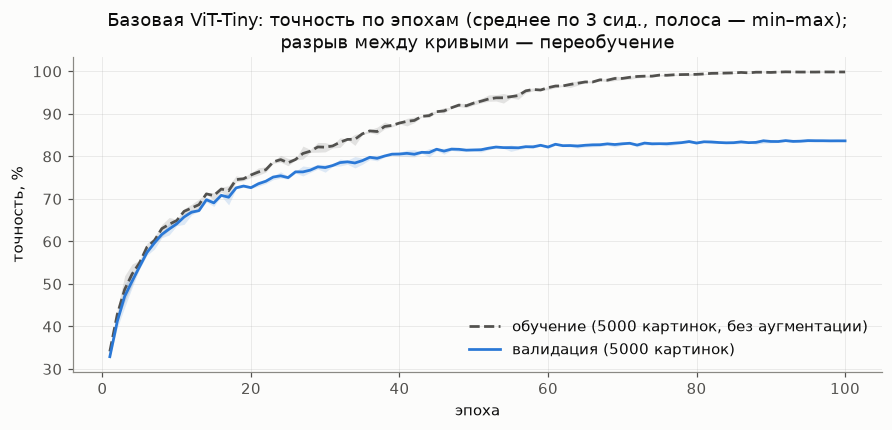

In [16]:
epochs = np.arange(1, EPOCHS + 1)
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
for key, label, color, ls in [("train_acc", f"обучение ({N_TRAIN_ACC} картинок, без аугментации)", PALETTE["uniform"], "--"),
                              ("val_acc", f"валидация ({N_VAL_USED} картинок)", PALETTE["erank"], "-")]:
    acc = 100 * np.array([[h[key] for h in base_rows[s]["history"]] for s in SEEDS])
    ax.plot(epochs, acc.mean(0), ls=ls, color=color, label=label, marker="o" if EPOCHS < 5 else None)
    if len(SEEDS) > 1:
        ax.fill_between(epochs, acc.min(0), acc.max(0), color=color, alpha=0.15, lw=0)
ax.set(xlabel="эпоха", ylabel="точность, %",
       title=f"Базовая ViT-Tiny: точность по эпохам (среднее по {len(SEEDS)} сид., полоса — min–max);\n"
             "разрыв между кривыми — переобучение")
ax.legend(loc="lower right")
plt.show()

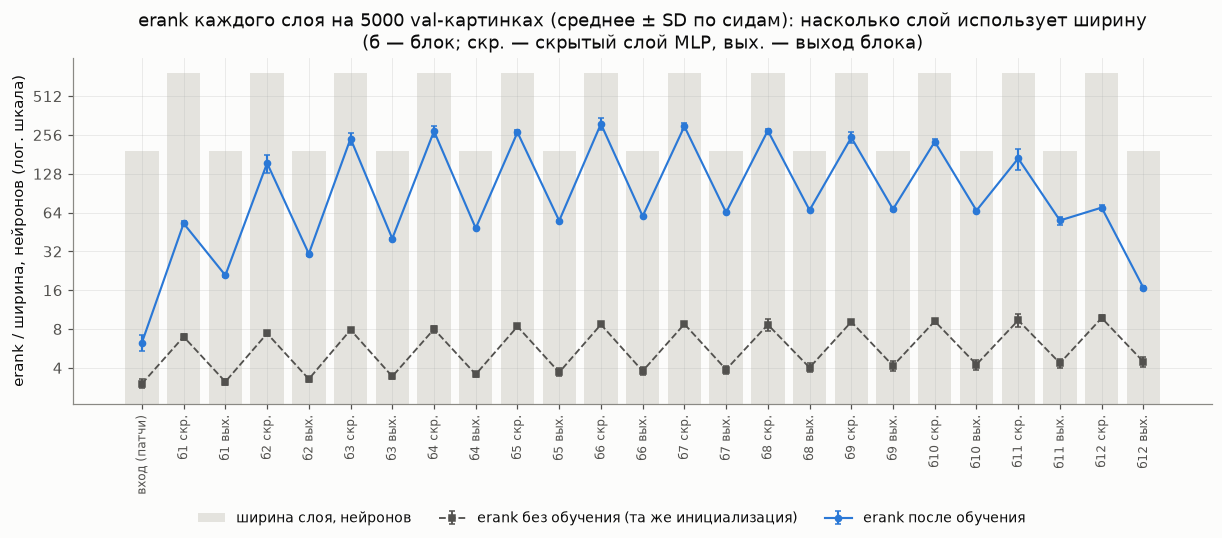

In [17]:
layers0 = base_rows[S0]["layers"]
labels = [layer_label(m["layer"]) for m in layers0]
trained = np.array([[m["erank_energy"] for m in base_rows[s]["layers"]] for s in SEEDS])
untrained = np.array([[m["erank_energy"] for m in base_rows[s]["untrained_layers"]] for s in SEEDS])
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
ax.bar(x, [m["width"] for m in layers0], color=BAR_GREY, label="ширина слоя, нейронов")
ax.errorbar(x, untrained.mean(0), yerr=sd(untrained), fmt="s--", color=PALETTE["uniform"], ms=4, lw=1.2, capsize=2,
            label="erank без обучения (та же инициализация)")
ax.errorbar(x, trained.mean(0), yerr=sd(trained), fmt="o-", color=PALETTE["erank"], ms=4, lw=1.4, capsize=2,
            label="erank после обучения")
log2_plain(ax)
ax.set_xticks(x, labels, rotation=90, fontsize=8)
ax.set(ylabel="erank / ширина, нейронов (лог. шкала)",
       title=f"erank каждого слоя на {N_VAL_USED} val-картинках (среднее ± SD по сидам): насколько слой использует ширину\n"
             "(б — блок; скр. — скрытый слой MLP, вых. — выход блока)")
fig.legend(loc="outside lower center", ncol=3, fontsize=9)
plt.show()

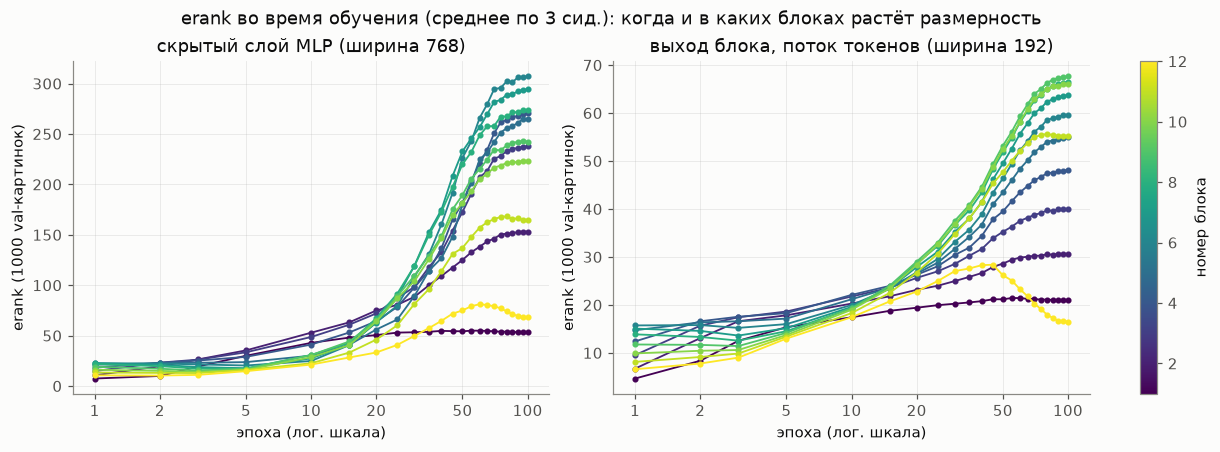

**Вывод.** База: test 83,39 ± 0,20% (n=3). erank скрытых слоёв после обучения 53–312 из 768 (максимум в блоке 6, минимум в блоке 1), без обучения 7–10; поток токенов 17–68 из 192. После эпохи 1 erank скрытых слоёв 7–23; между эпохами 95 и 100 средний erank скрытых слоёв изменился на +0,2.

In [18]:
probe_eps = [h["epoch"] for h in base_rows[S0]["history"] if "erank" in h]
er = np.array([[h["erank"] for h in base_rows[s]["history"] if "erank" in h] for s in SEEDS]).mean(0)  # (epochs, 25)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
for b in range(12):
    color = plt.cm.viridis(b / 11)
    axes[0].plot(probe_eps, er[:, 1 + 2 * b], color=color, marker="o", ms=3, lw=1.2)
    axes[1].plot(probe_eps, er[:, 2 + 2 * b], color=color, marker="o", ms=3, lw=1.2)
for ax, title in zip(axes, ["скрытый слой MLP (ширина 768)", "выход блока, поток токенов (ширина 192)"]):
    ax.set_xscale("log")
    ax.set_xticks([t for t in [1, 2, 5, 10, 20, 50, 100] if t <= max(probe_eps)],
                  [str(t) for t in [1, 2, 5, 10, 20, 50, 100] if t <= max(probe_eps)])
    ax.minorticks_off()
    ax.set(title=title, xlabel="эпоха (лог. шкала)")
axes[0].set_ylabel(f"erank ({N_PROBE} val-картинок)")
axes[1].set_ylabel(f"erank ({N_PROBE} val-картинок)")
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(1, 12), cmap="viridis"), ax=axes, label="номер блока")
fig.suptitle(f"erank во время обучения (среднее по {len(SEEDS)} сид.): когда и в каких блоках растёт размерность")
plt.show()

inner_tr, inner_un, out_tr = trained[:, 1::2].mean(0), untrained[:, 1::2].mean(0), trained[:, 2::2].mean(0)
base_acc = 100 * np.array([base_rows[s]["test_acc"] for s in SEEDS])
trend = (f"между эпохами {probe_eps[-2]} и {probe_eps[-1]} средний erank скрытых слоёв изменился на "
         f"{er[-1, 1::2].mean() - er[-2, 1::2].mean():+.1f}" if len(probe_eps) > 1 else "один замер")
display(Markdown(
    f"**Вывод.** База: test {base_acc.mean():.2f} ± {sd(base_acc):.2f}% (n={len(SEEDS)}). erank скрытых слоёв после "
    f"обучения {inner_tr.min():.0f}–{inner_tr.max():.0f} из 768 (максимум в блоке {inner_tr.argmax() + 1}, минимум в "
    f"блоке {inner_tr.argmin() + 1}), без обучения {inner_un.min():.0f}–{inner_un.max():.0f}; поток токенов "
    f"{out_tr.min():.0f}–{out_tr.max():.0f} из 192. После эпохи {probe_eps[0]} erank скрытых слоёв "
    f"{er[0, 1::2].min():.0f}–{er[0, 1::2].max():.0f}; {trend}."))

## Шаг 2. Какая мера лучше предсказывает, насколько можно сжать слой

Для каждого блока отдельно (остальные целые, без дообучения) измеряется **потребность** — наименьшее число
нейронов k, при котором точность на валидации падает не больше чем на 1 п.п.: (a) срез — остаются k нейронов с
наибольшей L1-нормой строки fc1; (b) PCA — fc2 читает только k главных направлений активаций (базис по 2000
обучающим картинкам). При k ≥ 154 два слоя ранга k не меньше исходного fc2 (k·(768+192) ≥ 768·192), fc2 остаётся
прежним: такие k не прогоняются, им приписывается точность полной сети, и в потребности они засчитываются как
проходящие — поэтому потребность PCA не больше первого такого k сетки (192 при полной сетке долей). Снизу сетка
ограничена наименьшим проверенным k (12 = 768/64 при полной сетке долей): если блок выдерживает и его, потребность —
лишь верхняя граница (в таблице «≤ 12»), а насколько меньше нейронов блоку хватило бы, не измерено. У таких блоков
потребность одинаковая, поэтому Spearman считается на частично совпадающих значениях (им даётся средний ранг).

С потребностью сравниваются (Spearman по 12 блокам для каждого сида, затем среднее): erank по λ (основной) и по σ
(определение Roy & Vetterli, 2007: $p_i=\sigma_i/\sum_j\sigma_j$, $\sigma_i=\sqrt{\lambda_i}$ — сингулярные числа
центрированной матрицы активаций), participation ratio, stable rank, число направлений с 90% / 99% энергии, erank до GELU (выход fc1), erank только
дисперсий нейронов (без корреляций) и вариант статьи arXiv 2607.19315 — erank ковариации 64 токенов **одной**
картинки, средний по 500 val-картинкам (NEW, в основной серии его не было; ограничен 63). Ширина слоя как ориентир
не определена: все блоки по 768.

In [19]:
def measure_points(seed: int) -> dict:
    """erank before GELU (fc1 output) and of the variances only (main series: step_measure_point), plus the
    per-image variant (NEW). All on the val pictures, base of `seed`."""
    base = bases[seed]

    def fn():
        x = data["x_val"]
        fc1 = channel_covariances(base, x, modules=[b.fc1 for b in base.blocks])  # before GELU
        act = channel_covariances(base, x)[1::2]  # the usual point: after GELU
        return {"fc1": [all_metrics(eigvals_desc(c)) for c in fc1],
                "diag": [all_metrics(c.diagonal().clamp(min=0).sort(descending=True).values.cpu()) for c in act],
                "per_image": per_image_erank(base, x[:N_PER_IMAGE])}

    return cached(f"points|{base_id(seed)}|n{N_PER_IMAGE}", fn)


points = {s: measure_points(s) for s in SEEDS}
measures = {}  # {seed: {measure: [12 values]}}
for s in SEEDS:
    measures[s] = block_measures(base_rows[s]["layers"])
    measures[s]["fc1"] = [m["erank_energy"] for m in points[s]["fc1"]]
    measures[s]["diag"] = [m["erank_energy"] for m in points[s]["diag"]]
    measures[s]["per_image"] = points[s]["per_image"]
inner0 = [m for m in base_rows[S0]["layers"] if m["layer"].endswith("inner")]
columns = {"erank_energy": "erank (после GELU)", "erank_sv": "erank по σ", "participation_ratio": "PR",
           "stable_rank": "stable rank", "energy90": "90% энергии", "energy99": "99% энергии",
           "fc1": "erank до GELU", "diag": "erank дисперсий", "per_image": "erank 1 картинки"}
table = pd.DataFrame({label: np.mean([measures[s][key] for s in SEEDS], axis=0) for key, label in columns.items()},
                     index=pd.Index(range(1, 13), name="блок"))
table["ранг (после GELU)"] = np.mean([[m["rank"] for m in base_rows[s]["layers"] if m["layer"].endswith("inner")]
                                      for s in SEEDS], axis=0)
table["ранг до GELU"] = np.mean([[m["rank"] for m in points[s]["fc1"]] for s in SEEDS], axis=0)
print(f"скрытые слои обученной базы, среднее по {len(SEEDS)} сид.; ширина каждого блока 768")
display(table.round(1))

скрытые слои обученной базы, среднее по 3 сид.; ширина каждого блока 768


,erank (после GELU),erank по σ,PR,stable rank,90% энергии,99% энергии,erank до GELU,erank дисперсий,erank 1 картинки,ранг (после GELU),ранг до GELU
блок,,,,,,,,,,,
1,52.7,321.0,25.3,9.0,60.3,305.3,17.0,342.8,16.6,768.0,191.0
2,154.7,509.4,66.1,18.4,217.0,585.0,19.9,436.8,24.7,768.0,191.0
3,240.0,565.9,101.5,20.4,318.7,619.0,24.6,537.3,26.2,768.0,191.0
4,274.1,593.9,112.1,19.8,357.7,640.0,25.5,581.5,21.6,768.0,191.0
5,268.2,586.4,102.9,16.7,356.7,626.0,27.6,587.9,20.6,768.0,191.0
6,312.0,584.9,157.2,31.8,366.3,608.3,30.9,579.0,21.7,768.0,191.0
7,298.4,538.0,160.9,33.2,335.0,539.0,31.9,527.9,22.2,768.0,191.0
8,276.6,496.8,156.5,37.3,302.3,486.0,31.1,482.2,22.1,768.0,191.0
9,244.7,451.3,139.3,33.8,266.0,429.7,31.8,437.9,21.2,768.0,191.0


In [20]:
def sensitivity(seed: int) -> list[dict]:
    """Main series: step_sensitivity. One block at a time: L1 cut to k neurons, or fc2 reading only the top-k PCA
    directions; val accuracy, no training. One cached unit per block."""
    base = bases[seed]
    widths = base.inner_widths()
    full = cached(f"sens|full|{base_id(seed)}",
                  lambda: {"kind": "full", "seed": seed, "val_acc": evaluate(base, data["x_val"], data["y_val"])["acc"]})
    rows = [full]
    l1 = neuron_scores(base, "l1")
    x_pca = data["x_train"][PCA_CALIB[0]:PCA_CALIB[1]]  # training pictures, not val
    stats = {}
    for b, width in enumerate(widths):
        ks = sorted({max(1, round(f * width)) for f in SENS_FRACTIONS})
        out_dim = base.blocks[b].fc2.out_features

        def fn():
            out = []
            for k in ks:
                for kind in ["prune", "pca"]:
                    row = {"kind": kind, "block": b + 1, "width": width, "k": k, "seed": seed}
                    if kind == "prune":
                        keep = [torch.arange(w) for w in widths]
                        keep[b] = top_k(l1[b], k)
                        model = keep_inner(base, keep)
                    elif k * (width + out_dim) >= width * out_dim:  # lowrank_fc2 would keep fc2 unchanged
                        out.append({**row, "val_acc": full["val_acc"], "skipped": True})
                        continue
                    else:
                        if not stats:
                            stats["covs"], stats["means"] = channel_covariances(base, x_pca), inner_means(base, x_pca)
                        ranks = list(widths)
                        ranks[b] = k
                        model = lowrank_fc2(base, ranks, "pca", [b], stats["covs"], stats["means"])
                    out.append({**row, "val_acc": evaluate(model, data["x_val"], data["y_val"])["acc"]})
            return {"rows": out}

        rows += cached(f"sens|b{b + 1}|{base_id(seed)}|k={ks}", fn)["rows"]
    return rows


sens = [r for s in SEEDS for r in sensitivity(s)]
need = {kind: needed_widths(sens, kind, SENS_DROP) for kind in ["prune", "pca"]}
NEED_L1 = {s: [need["prune"][(s, b)] for b in range(1, 13)] for s in SEEDS}
rhos = {kind: sensitivity_rhos(need[kind], measures) for kind in need}
# NEW: a need equal to the smallest k tried is only an upper bound (the block passes even there)
min_k = {kind: {key: min(r["k"] for r in by(sens, kind=kind, seed=key[0], block=key[1])) for key in need[kind]}
         for kind in need}
at_floor = {kind: {key: need[kind][key] == min_k[kind][key] for key in need[kind]} for kind in need}
K_MIN = min(min(v.values()) for v in min_k.values())


def need_cell(kind: str, s: int, b: int) -> str:
    return f"≤ {need[kind][(s, b)]}" if at_floor[kind][(s, b)] else str(need[kind][(s, b)])


print(f"потребность блока, нейронов из 768 (падение val не больше {SENS_DROP:g} п.п.); «≤ k» — блок выдерживает и "
      f"наименьшее проверенное k ({K_MIN}), это лишь верхняя граница")
display(pd.DataFrame({f"потребность L1, сид {s}": [need_cell("prune", s, b) for b in range(1, 13)] for s in SEEDS}
                     | {f"потребность PCA, сид {s}": [need_cell("pca", s, b) for b in range(1, 13)] for s in SEEDS},
                     index=pd.Index(range(1, 13), name="блок")).T)
print(f"блоков из 12 на наименьшем k (сиды {', '.join(map(str, SEEDS))}): " + "; ".join(
    f"{label} — " + " / ".join(str(sum(at_floor[kind][(s, b)] for b in range(1, 13))) for s in SEEDS)
    for kind, label in [("prune", "L1"), ("pca", "PCA")]))

потребность блока, нейронов из 768 (падение val не больше 1 п.п.); «≤ k» — блок выдерживает и наименьшее проверенное k (12), это лишь верхняя граница


блок,1,2,3,4,5,6,7,8,9,10,11,12
"потребность L1, сид 0",624,384,288,144,192,24,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12
"потребность L1, сид 1",576,192,144,240,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,72
"потребность L1, сид 2",624,96,288,144,96,≤ 12,≤ 12,24,≤ 12,≤ 12,≤ 12,96
"потребность PCA, сид 0",48,48,48,24,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12
"потребность PCA, сид 1",48,48,24,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12
"потребность PCA, сид 2",48,24,24,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12,≤ 12


блоков из 12 на наименьшем k (сиды 0, 1, 2): L1 — 6 / 7 / 5; PCA — 8 / 9 / 9


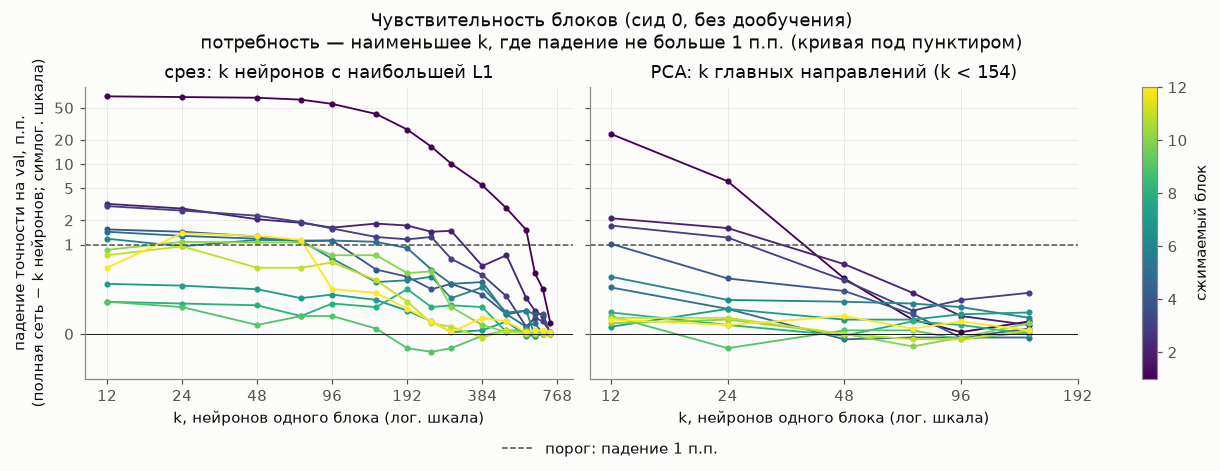

In [21]:
ref0 = 100 * by(sens, kind="full", seed=S0)[0]["val_acc"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True, layout="constrained")
drops = []
for ax, kind, title in zip(axes, ["prune", "pca"], ["срез: k нейронов с наибольшей L1",
                                                    "PCA: k главных направлений (k < 154)"]):
    for b in range(1, 13):
        rows = sorted((r for r in by(sens, kind=kind, seed=S0, block=b) if not r.get("skipped")), key=lambda r: r["k"])
        if rows:
            drop = [ref0 - 100 * r["val_acc"] for r in rows]
            drops += drop
            ax.plot([r["k"] for r in rows], drop, color=plt.cm.viridis((b - 1) / 11), marker="o", ms=3, lw=1.2)
    ax.axhline(SENS_DROP, color=PALETTE["uniform"], ls="--", lw=1, label=f"порог: падение {SENS_DROP:g} п.п.")
    ax.axhline(0, color=INK, lw=0.6)
    plain_log_axis(ax, [12, 24, 48, 96, 192, 384, 768])
    ax.set(title=title, xlabel="k, нейронов одного блока (лог. шкала)")
axes[0].set_yscale("symlog", linthresh=1)  # linear in [-1, 1] p.p., logarithmic beyond: both small and large drops
yticks = [t for t in [-5, -2, -1, 0, 1, 2, 5, 10, 20, 50, 100] if min(drops + [0]) - 0.5 <= t <= max(drops + [1]) * 1.1]
axes[0].set_yticks(yticks, [f"{t:g}" for t in yticks])
axes[0].set_ylim(min(drops + [0]) - 0.3, max(drops + [SENS_DROP]) * 1.3)
axes[0].minorticks_off()
axes[0].set_ylabel("падение точности на val, п.п.\n(полная сеть − k нейронов; симлог. шкала)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center")
fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(1, 12), cmap="viridis"), ax=axes, label="сжимаемый блок")
fig.suptitle(f"Чувствительность блоков (сид {S0}, без дообучения)\nпотребность — наименьшее k, где падение "
             f"не больше {SENS_DROP:g} п.п. (кривая под пунктиром)")
plt.show()

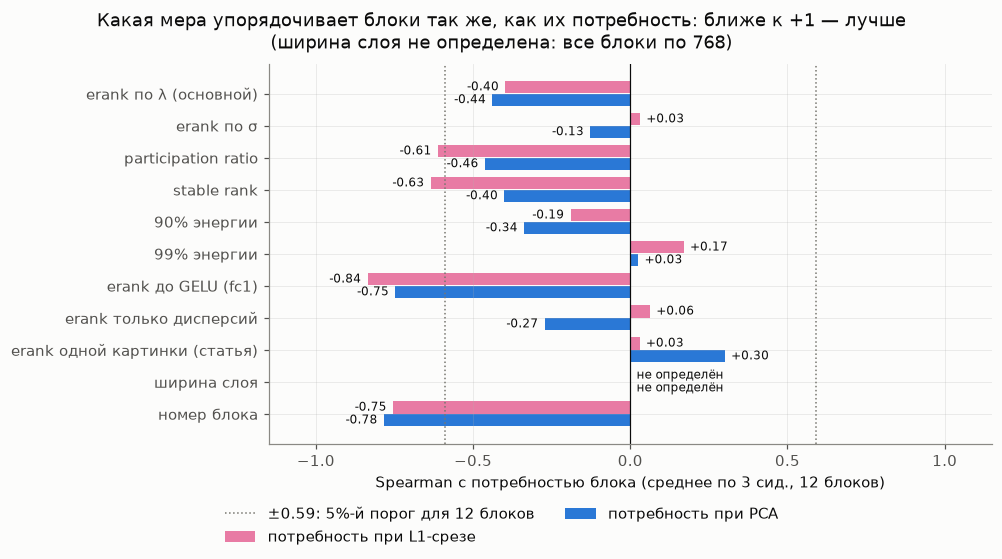

In [22]:
order = ["erank_energy", "erank_sv", "participation_ratio", "stable_rank", "energy90", "energy99", "fc1", "diag",
         "per_image", "width", "depth"]
names = {**MEASURES, "erank_energy": "erank по λ (основной)", "fc1": "erank до GELU (fc1)",
         "diag": "erank только дисперсий", "per_image": "erank одной картинки (статья)"}
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
for shift, kind, label, key in [(-0.2, "prune", "потребность при L1-срезе", "l1"), (0.2, "pca", "потребность при PCA", "pca")]:
    vals = np.array([rhos[kind][m] for m in order])
    ax.barh(y + shift, np.nan_to_num(vals), height=0.38, color=PALETTE[key], label=label)
    for yi, v in zip(y + shift, vals):
        ax.text(v + (0.02 if v >= 0 else -0.02) if np.isfinite(v) else 0.02, yi, rho_text(v), va="center",
                ha="left" if not np.isfinite(v) or v >= 0 else "right", fontsize=8, color=INK)
ax.axvline(0, color=INK, lw=0.8)
for sign in (-1, 1):
    ax.axvline(sign * RHO_CRIT, color=NOTE_GREY, ls=":", lw=1, label=f"±{RHO_CRIT:.2f}: 5%-й порог для 12 блоков" if sign > 0 else None)
ax.set_yticks(y, [names[m] for m in order])
ax.invert_yaxis()
ax.set_xlim(-1.15, 1.15)
ax.set(xlabel=f"Spearman с потребностью блока (среднее по {len(SEEDS)} сид., 12 блоков)")
fig.suptitle("Какая мера упорядочивает блоки так же, как их потребность: ближе к +1 — лучше\n"
             "(ширина слоя не определена: все блоки по 768)")
fig.legend(loc="outside lower center", ncol=2)
plt.show()

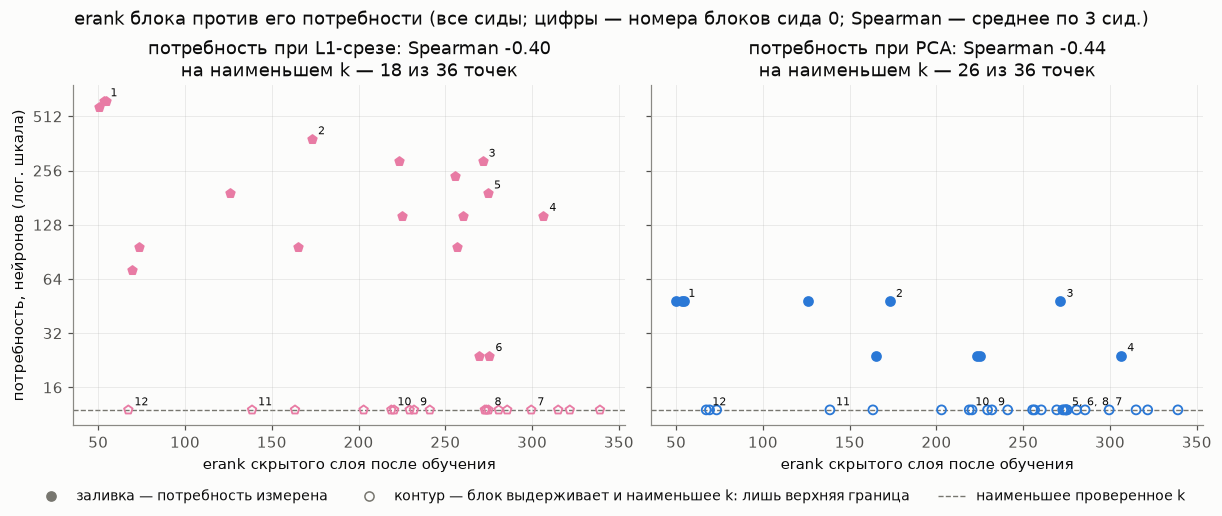

**Вывод.** Spearman erank с L1-потребностью −0,40, с PCA-потребностью −0,44; номер блока: −0,75 / −0,78. Лучшая мера для L1-потребности: нет — ни у одной меры ρ не достигает 0,59 (наибольший +0,17 — 99% энергии); у меры «erank по λ (основной)» знак обратный (ρ = −0,40): блокам с большим erank скорее нужно меньше нейронов; обратный порядок с ρ ≤ −0,59: erank до GELU (fc1) (−0,84), stable rank (−0,63), participation ratio (−0,61). Для PCA-потребности: нет — ни у одной меры ρ не достигает 0,59 (наибольший +0,30 — erank одной картинки (статья)); у меры «erank по λ (основной)» знак обратный (ρ = −0,44): блокам с большим erank скорее нужно меньше нейронов; обратный порядок с ρ ≤ −0,59: erank до GELU (fc1) (−0,75). Больше всего нейронов при срезе нужно блоку 1 (в среднем 608), его erank 53. Вариант одной картинки: +0,03 / +0,30. Потребность на наименьшем проверенном k (12), то есть лишь верхняя граница, — у L1 в 18 из 36 пар блок × сид, у PCA — в 26 из 36; блоки выше него во всех сидах: L1 — 1–4, PCA — 1–3. Порядок внутри группы на наименьшем k не измерен (одинаковые значения получают средний ранг), поэтому ρ показывает в основном, какие блоки поднимаются выше него; у L1- и PCA-потребности на наименьшем k половина пар или больше — оценка ρ грубая.

In [23]:
n_pairs = len(SEEDS) * 12
floor_n = {kind: sum(at_floor[kind].values()) for kind in at_floor}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True, layout="constrained")
for ax, kind, label, key in zip(axes, ["prune", "pca"], ["L1-срезе", "PCA"], ["l1", "pca"]):
    points = [(measures[s]["erank_energy"][b - 1], need[kind][(s, b)], at_floor[kind][(s, b)])
              for s in SEEDS for b in range(1, 13)]
    for floor, face in [(False, PALETTE[key]), (True, "none")]:  # hollow: need at the smallest k, an upper bound
        sel = [(x, y) for x, y, f in points if f == floor]
        if sel:
            ax.scatter(*zip(*sel), marker=MARKERS[key], s=34, facecolors=face, edgecolors=PALETTE[key],
                       linewidths=1.2, zorder=3)
    for k in sorted(set(min_k[kind].values())):
        ax.axhline(k, color=NOTE_GREY, ls="--", lw=0.9, zorder=1)
    labels = {}  # blocks of seed S0 at (almost) the same point share one label: "5, 6, 8"
    for b in range(1, 13):
        x, y = measures[S0]["erank_energy"][b - 1], need[kind][(S0, b)]
        spot = next((p for p in labels if p[1] == y and abs(p[0] / x - 1) < 0.02), (x, y))
        labels.setdefault(spot, []).append(b)
    for spot, blocks in labels.items():
        ax.annotate(", ".join(map(str, blocks)), spot, textcoords="offset points", xytext=(4, 3), fontsize=7, color=INK)
    log2_plain(ax)
    ax.set(xlabel="erank скрытого слоя после обучения",
           title=f"потребность при {label}: Spearman {rho_text(rhos[kind]['erank_energy'])}\n"
                 f"на наименьшем k — {floor_n[kind]} из {n_pairs} точек")
axes[0].set_ylabel("потребность, нейронов (лог. шкала)")
fig.legend(handles=[plt.Line2D([], [], ls="none", marker="o", color=NOTE_GREY, label="заливка — потребность измерена"),
                    plt.Line2D([], [], ls="none", marker="o", mfc="none", color=NOTE_GREY,
                               label="контур — блок выдерживает и наименьшее k: лишь верхняя граница"),
                    plt.Line2D([], [], ls="--", lw=0.9, color=NOTE_GREY, label="наименьшее проверенное k")],
           loc="outside lower center", ncol=3, fontsize=9)
fig.suptitle(f"erank блока против его потребности (все сиды; цифры — номера блоков сида {S0}; "
             f"Spearman — среднее по {len(SEEDS)} сид.)")
plt.show()

best_measure = {kind: measure_verdict(rhos[kind], names) for kind in rhos}
top = max(range(1, 13), key=lambda b: np.mean([need["prune"][(s, b)] for s in SEEDS]))
above = {kind: [b for b in range(1, 13) if not any(at_floor[kind][(s, b)] for s in SEEDS)] for kind in at_floor}
floor_text = ""
if all(n == n_pairs for n in floor_n.values()):
    floor_text = (f" Потребность всех блоков — на наименьшем проверенном k ({K_MIN}), то есть лишь верхняя граница: "
                  "порядок блоков по потребности не измерен.")
elif any(floor_n.values()):
    rough = [label for kind, label in [("prune", "L1"), ("pca", "PCA")] if 2 * floor_n[kind] >= n_pairs]
    floor_text = (
        f" Потребность на наименьшем проверенном k ({K_MIN}), то есть лишь верхняя граница, — у L1 в {floor_n['prune']} "
        f"из {n_pairs} пар блок × сид, у PCA — в {floor_n['pca']} из {n_pairs}; блоки выше него во всех сидах: L1 — "
        f"{blocks_text(above['prune'])}, PCA — {blocks_text(above['pca'])}. Порядок внутри группы на наименьшем k не "
        "измерен (одинаковые значения получают средний ранг), поэтому ρ показывает в основном, какие блоки "
        "поднимаются выше него"
        + (f"; у {'- и '.join(rough)}-потребности на наименьшем k половина пар или больше — оценка ρ грубая"
           if rough else "") + ".")
display(Markdown(
    f"**Вывод.** Spearman erank с L1-потребностью {rho_text(rhos['prune']['erank_energy'])}, с PCA-потребностью "
    f"{rho_text(rhos['pca']['erank_energy'])}; номер блока: {rho_text(rhos['prune']['depth'])} / "
    f"{rho_text(rhos['pca']['depth'])}. Лучшая мера для L1-потребности: {best_measure['prune']}. Для PCA-потребности: "
    f"{best_measure['pca']}. Больше всего нейронов при срезе нужно "
    f"блоку {top} (в среднем {np.mean([need['prune'][(s, top)] for s in SEEDS]):.0f}), его erank "
    f"{np.mean([measures[s]['erank_energy'][top - 1] for s in SEEDS]):.0f}. Вариант одной картинки: "
    f"{rho_text(rhos['prune']['per_image'])} / {rho_text(rhos['pca']['per_image'])}." + floor_text))

## Шаг 3. Ширины по erank и бейзлайны: обучение с нуля

Ширины скрытых слоёв подбираются под потолок параметров и обучаются с нуля по тому же рецепту (100 эпох, 3 сида).
`fit_budget`: ширины пропорциональны выбранной величине — erank, исходной ширине (uniform), случайной доле от 20 до
100% (random) или L1-потребности шага 2 (в духе Li et al., 2017) — не шире 768 и не уже 8; общий масштаб растёт на 1%,
пока сеть помещается в бюджет. `taylor_global` (Molchanov et al., 2019): на каждый скрытый нейрон ставится «вентиль»
g = 1, важность — (∂L/∂g)² = (Σ по картинкам батча и токенам a·∂L/∂a)², среднее по 20 обучающим батчам по 256
картинок; после резерва 8 лучших нейронов каждого блока остальные добавляются по убыванию важности, пока помещаются.
Не применимы: γ BatchNorm и Network Slimming (в ViT нет BatchNorm, только LayerNorm); HRank определён для
свёрточных карт признаков, и на токены MLP ViT в основной серии не переносился. Вместо сужения — low-rank fc2: пара слоёв ранга r = 0,5 / 1 / 2 × erank по главным
направлениям активаций (PCA, на 5000 val-картинках) или по SVD весов fc2, до и после 5 эпох дообучения; при
r ≥ 154 разложение не экономит параметры, и fc2 этого блока остаётся прежним.

In [24]:
cost_p, cost_m = inner_cost(bases[S0], "params"), inner_cost(bases[S0], "macs")
floor_params = size_fn(bases[S0], "params")([FLOOR] * 12)
budget_table = []
for b in BUDGETS:
    w = fit_budget(bases[S0].inner_widths(), int(b * FULL_PARAMS), bases[S0])
    budget_table.append({"потолок": f"{b:.0%}", "uniform ширина MLP": w[0], "доля ширины 768": f"{w[0] / 768:.0%}",
                         "параметры, %": 100 * size_fn(bases[S0], "params")(w) / FULL_PARAMS,
                         "MACs, %": 100 * size_fn(bases[S0], "macs")(w) / FULL_MACS})
display(pd.DataFrame(budget_table).round(2).set_index("потолок"))
fixed_share = 1 - cost_p[0] * 768 * 12 / FULL_PARAMS
display(Markdown(
    f"Один скрытый нейрон стоит {int_text(cost_p[0])} параметров и {int_text(cost_m[0])} MACs "
    f"({'одинаково во всех' if len(set(cost_p)) == 1 else 'по-разному в'} {len(cost_p)} блоках), поэтому у двух сетей "
    f"с равным числом параметров равны и MACs — "
    f"отдельные бюджеты по MACs не нужны (но проценты двух ресурсов различаются из-за постоянной части). Часть вне MLP — "
    f"{fixed_share:.1%} параметров; сеть с {FLOOR} нейронами в каждом блоке — {floor_params / FULL_PARAMS:.1%}, поэтому "
    f"бюджеты 25% и 10% недостижимы. Потолок 50% параметров — это MLP шириной {budget_table[0]['uniform ширина MLP']} из 768."))

,uniform ширина MLP,доля ширины 768,"параметры, %","MACs, %"
потолок,,,,
50%,187,24%,49.94,52.30
40%,71,9%,39.95,42.78


Один скрытый нейрон стоит 385 параметров и 24 576 MACs (одинаково во всех 12 блоках), поэтому у двух сетей с равным числом параметров равны и MACs — отдельные бюджеты по MACs не нужны (но проценты двух ресурсов различаются из-за постоянной части). Часть вне MLP — 33,8% параметров; сеть с 8 нейронами в каждом блоке — 34,5%, поэтому бюджеты 25% и 10% недостижимы. Потолок 50% параметров — это MLP шириной 187 из 768.

In [25]:
def widths_for(method: str, seed: int, budget: float) -> list[int]:
    """Widths of `method` at a fraction of the full parameters (cached: Taylor scores are not bit-stable on GPU)."""
    return cached(f"widths|{method}|{budget}|{base_id(seed)}",
                  lambda: {"widths": alloc_widths(method, bases[seed], base_rows[seed]["layers"], int(budget * FULL_PARAMS),
                                                  seed, data, need=NEED_L1[seed])})["widths"]


def scratch(widths, seed: int) -> dict:
    """Train ViT-Tiny with these MLP widths from scratch (main series: step_alloc). Identical (widths, seed) pairs
    are trained once and reused by every method, budget and iteration that proposes them."""
    widths = [int(w) for w in widths]

    def fn():
        torch.manual_seed(seed)
        model = ViT(widths).to(DEVICE)
        history = train(model, data, EPOCHS, LR, seed=seed, verbose=False, **TRAIN_KW)
        metrics = layer_metrics(model, data["x_val"])
        return {"widths": widths, "seed": seed, "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
                "val_acc": history[-1]["val_acc"],
                "train_acc": evaluate(model, data["x_train"][:N_TRAIN_ACC], data["y_train"][:N_TRAIN_ACC])["acc"],
                "train_minutes": round(sum(h["seconds"] for h in history) / 60, 2),
                "inner_layers": [m for m in metrics if m["layer"].endswith("inner")], **describe(model)}

    return cached(f"scratch|vit_tiny|cifar10|w={widths}|s{seed}|e{EPOCHS}", fn)


alloc = []
for seed in SEEDS:
    for budget in BUDGETS:
        for method in ALLOC_METHODS:
            row = scratch(widths_for(method, seed, budget), seed)
            alloc.append({**row, "method": method, "budget": budget, "seed": seed})
acc_table = pd.DataFrame([{"метод": METHOD[r["method"]][0], "потолок": f"{r['budget']:.0%}", "test": 100 * r["test_acc"]}
                          for r in alloc]).groupby(["потолок", "метод"], sort=False)["test"].agg(["mean", "std", "count"])
display(acc_table.round(2).rename(columns={"mean": "test, %", "std": "SD", "count": "n"}))

test, %    SD  n
потолок метод                                 
50%     uniform (равномерно)    82.81  0.34  3
        случайные ширины        83.08  0.11  3
        erank                   83.04  0.45  3
        Taylor (глобально)      83.17  0.03  3
        L1-потребность блока    83.10  0.29  3
40%     uniform (равномерно)    81.73  0.25  3
        случайные ширины        81.99  0.28  3
        erank                   81.79  0.24  3
        Taylor (глобально)      82.39  0.11  3
        L1-потребность блока    82.59  0.47  3

In [26]:
_pca_stats = {}


def pca_stats(seed: int):
    """Covariances and means of the base on all val pictures (main series: lowrank_conv2 with x = x_val)."""
    if seed not in _pca_stats:
        _pca_stats[seed] = (channel_covariances(bases[seed], data["x_val"]), inner_means(bases[seed], data["x_val"]))
    return _pca_stats[seed]


def lowrank_run(seed: int, mult: float, basis: str) -> dict:
    """Main series: step_lowrank. fc2 of every block -> two layers of rank ~ mult x erank (unless that saves
    nothing), accuracy before and after LOWRANK_FT_EPOCHS of fine-tuning."""
    base = bases[seed]
    eranks = inner(base_rows[seed]["layers"], "erank_energy")
    ranks = [min(w, max(4, round(mult * e))) for e, w in zip(eranks, base.inner_widths())]

    def fn():
        covs, means = pca_stats(seed) if basis == "pca" else (None, None)
        model = lowrank_fc2(base, ranks, basis, None, covs, means)
        row = {"basis": basis, "mult": mult, "ranks": ranks, "seed": seed,
               "changed_blocks": sum(isinstance(b.fc2, nn.Sequential) for b in model.blocks),
               "val_acc_raw": evaluate(model, data["x_val"], data["y_val"])["acc"],
               "test_acc_before_ft": evaluate(model, data["x_test"], data["y_test"])["acc"],
               "params": count_params(model), "macs": count_macs(model)}
        train(model, data, LOWRANK_FT_EPOCHS, FT_LR, seed=seed, verbose=False, **TRAIN_KW)
        return {**row, "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"]}

    return cached(f"lowrank|{basis}|{mult}|{base_id(seed)}|ft{LOWRANK_FT_EPOCHS}", fn)


lowrank = [lowrank_run(s, mult, basis) for s in SEEDS for mult in LOWRANK_MULTS for basis in ["pca", "svd"]]
display(pd.DataFrame([{"базис": BASIS[r["basis"]][0], "ранг × erank": r["mult"], "блоков с low-rank fc2": r["changed_blocks"],
                       "параметры, %": 100 * r["params"] / FULL_PARAMS, "test до FT, %": 100 * r["test_acc_before_ft"],
                       "test после FT, %": 100 * r["test_acc"]} for r in lowrank])
        .groupby(["базис", "ранг × erank"], sort=False).mean().round(2))

,,блоков с low-rank fc2,"параметры, %","test до FT, %","test после FT, %"
базис,ранг × erank,,,,
PCA активаций,0.5,11.00,90.00,79.59,81.95
SVD весов,0.5,11.00,90.00,77.68,83.05
PCA активаций,1.0,2.67,96.44,82.84,82.94
SVD весов,1.0,2.67,96.44,83.37,83.17
PCA активаций,2.0,2.00,98.89,83.27,83.14
SVD весов,2.0,2.00,98.89,83.45,83.23


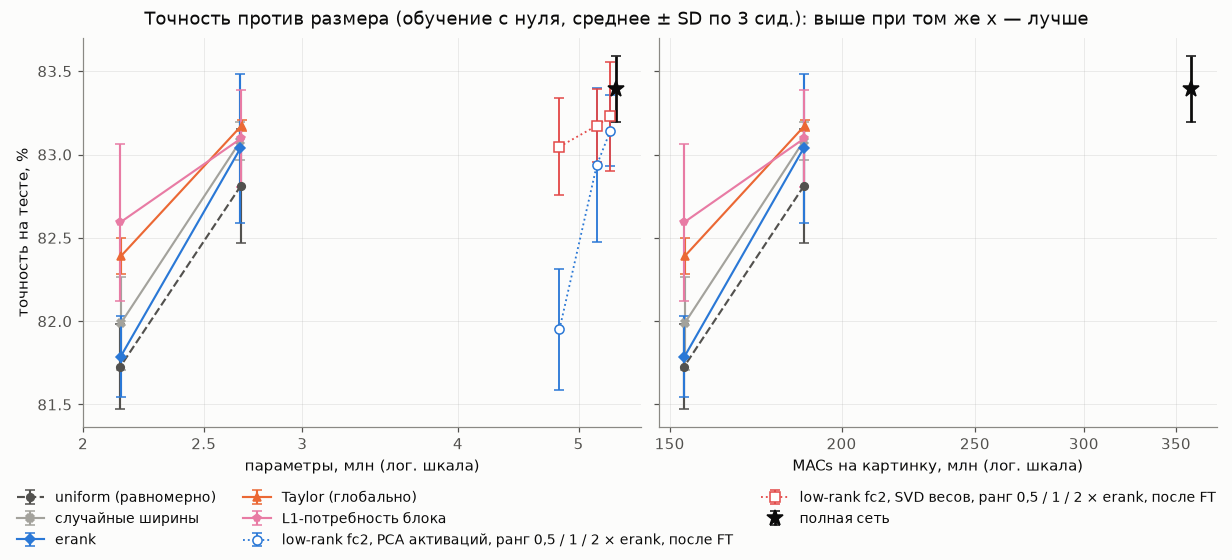

In [27]:
def acc_points(rows, key="test_acc"):
    acc = 100 * np.array([r[key] for r in rows])
    return acc.mean(), sd(acc)


full_acc, full_sd = acc_points(base_rows.values())
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, layout="constrained")
for ax, resource, full, scale, ticks in [(axes[0], "params", FULL_PARAMS, 1e6, [2, 2.5, 3, 4, 5]),
                                         (axes[1], "macs", FULL_MACS, 1e6, [150, 200, 250, 300, 350])]:
    for method in ALLOC_METHODS:
        pts = [(np.mean([r[resource] for r in by(alloc, method=method, budget=b)]) / scale,
                *acc_points(by(alloc, method=method, budget=b))) for b in BUDGETS]
        xs, ys, es = zip(*pts)
        ax.errorbar(xs, ys, yerr=es, capsize=3, ms=5, lw=1.4, **mstyle(method))
    if resource == "params":
        for basis in ["pca", "svd"]:
            label, key = BASIS[basis]
            pts = [(np.mean([r["params"] for r in by(lowrank, basis=basis, mult=m)]) / scale,
                    *acc_points(by(lowrank, basis=basis, mult=m))) for m in LOWRANK_MULTS]
            xs, ys, es = zip(*pts)
            ax.errorbar(xs, ys, yerr=es, color=PALETTE[key], marker=MARKERS[key], mfc="white", ls=":", lw=1.2,
                        capsize=3, label=f"low-rank fc2, {label}, ранг 0,5 / 1 / 2 × erank, после FT")
    ax.errorbar([full / scale], [full_acc], yerr=[full_sd], color=FULL_COLOR, marker="*", ms=11, capsize=3,
                ls="none", label="полная сеть")
    ax.set_xscale("log")
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.minorticks_off()
    ax.set_xlabel("параметры, млн (лог. шкала)" if resource == "params" else "MACs на картинку, млн (лог. шкала)")
axes[0].set_ylabel("точность на тесте, %")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, fontsize=9)
fig.suptitle(f"Точность против размера (обучение с нуля, среднее ± SD по {len(SEEDS)} сид.): выше при том же x — лучше")
plt.show()

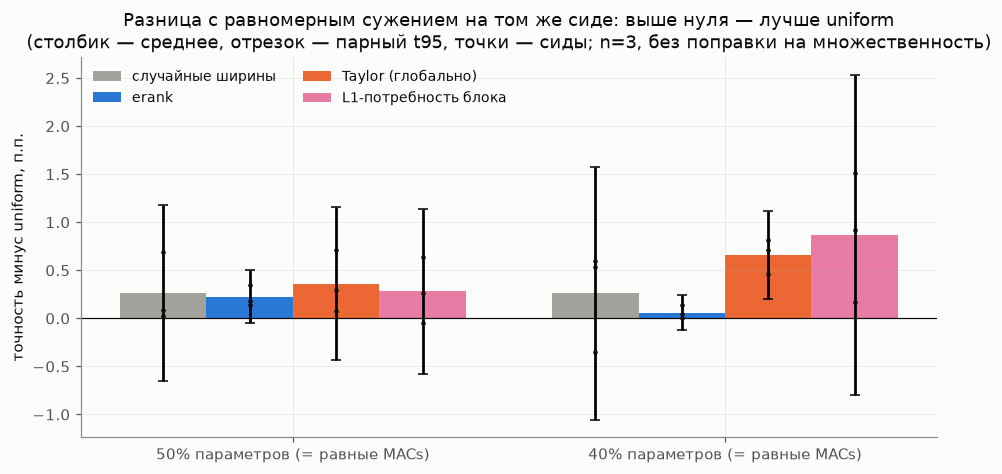

In [28]:
others = [m for m in ALLOC_METHODS if m != "uniform"]
width = 0.8 / len(others)
fig, ax = plt.subplots(figsize=(8.5, 4.2), layout="constrained")
for i, method in enumerate(others):
    xs = np.arange(len(BUDGETS)) + (i - (len(others) - 1) / 2) * width
    summaries = [paired_summary(paired_diffs(alloc, method, b)) for b in BUDGETS]
    ax.bar(xs, [s["mean_pp"] for s in summaries], width=width, yerr=[half_ci(s) for s in summaries], capsize=3,
           color=mstyle(method)["color"], label=METHOD[method][0])
    for x0, b in zip(xs, BUDGETS):
        d = paired_diffs(alloc, method, b)
        ax.plot([x0] * len(d), d, ls="none", marker=".", color=INK, ms=4)
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(range(len(BUDGETS)), [f"{b:.0%} параметров (= равные MACs)" for b in BUDGETS])
ax.set(ylabel="точность минус uniform, п.п.",
       title="Разница с равномерным сужением на том же сиде: выше нуля — лучше uniform\n"
             f"(столбик — среднее, отрезок — парный t95, точки — сиды; n={len(SEEDS)}, без поправки на множественность)")
ax.legend(ncol=2, fontsize=9)
plt.show()

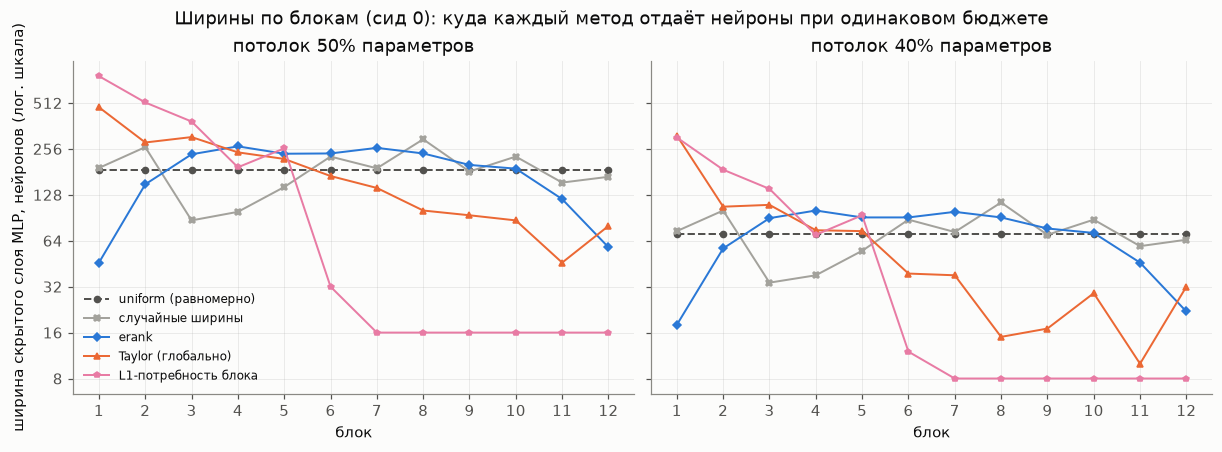

**Вывод.** Разница с uniform, п.п. [t95]: при 50% (uniform 82,81%) случайные ширины +0,27 [−0,65; +1,18] (n=3), erank +0,22 [−0,05; +0,50] (n=3), Taylor (глобально) +0,36 [−0,44; +1,16] (n=3), L1-потребность блока +0,28 [−0,58; +1,14] (n=3); при 40% (uniform 81,73%) случайные ширины +0,26 [−1,06; +1,58] (n=3), erank +0,06 [−0,12; +0,24] (n=3), Taylor (глобально) +0,66 [+0,21; +1,12] (n=3), L1-потребность блока +0,87 [−0,80; +2,53] (n=3). MACs любой сети отличаются от uniform того же бюджета не больше чем на 0,18%, поэтому график по MACs повторяет график по параметрам, а регрессия «точность ~ ln MACs + ln параметров» здесь неприменима (MACs — линейная функция параметров). Low-rank fc2 с рангом = erank заменяет fc2 в среднем в 2,7 из 12 блоков (где ранг ≥ 154, разложение не экономит и fc2 остаётся прежним), сеть сохраняет 96,4% параметров; test PCA 82,84 → 82,94%, SVD 83,37 → 83,17% до / после FT.

In [29]:
fig, axes = plt.subplots(1, len(BUDGETS), figsize=(11, 4), sharey=True, layout="constrained")
for ax, budget in zip(np.atleast_1d(axes), BUDGETS):
    for method in ALLOC_METHODS:
        ax.plot(range(1, 13), by(alloc, method=method, budget=budget, seed=S0)[0]["widths"], ms=4, lw=1.3,
                **mstyle(method))
    log2_plain(ax)
    ax.set_xticks(range(1, 13))
    ax.set(title=f"потолок {budget:.0%} параметров", xlabel="блок")
np.atleast_1d(axes)[0].set_ylabel("ширина скрытого слоя MLP, нейронов (лог. шкала)")
np.atleast_1d(axes)[0].legend(fontsize=8)
fig.suptitle(f"Ширины по блокам (сид {S0}): куда каждый метод отдаёт нейроны при одинаковом бюджете")
plt.show()

summ = {(m, b): paired_summary(paired_diffs(alloc, m, b)) for m in others for b in BUDGETS}
macs_gap = max(abs(r["macs"] / by(alloc, method="uniform", budget=r["budget"], seed=r["seed"])[0]["macs"] - 1) for r in alloc)
lr1 = by(lowrank, mult=1)
display(Markdown(
    "**Вывод.** Разница с uniform, п.п. [t95]: " + "; ".join(
        f"при {b:.0%} (uniform {acc_points(by(alloc, method='uniform', budget=b))[0]:.2f}%) "
        + ", ".join(f"{METHOD[m][0]} {ci_text(summ[(m, b)])}" for m in others) for b in BUDGETS)
    + f". MACs любой сети отличаются от uniform того же бюджета не больше чем на "
    f"{100 * macs_gap:.2f}%, поэтому график по MACs повторяет график по параметрам, а регрессия «точность ~ ln MACs + "
    f"ln параметров» здесь неприменима (MACs — линейная функция параметров). Low-rank fc2 с рангом = erank заменяет fc2 "
    f"в среднем в {np.mean([r['changed_blocks'] for r in lr1]):.1f} из 12 блоков (где ранг ≥ 154, разложение не экономит "
    f"и fc2 остаётся прежним), сеть сохраняет {100 * np.mean([r['params'] for r in lr1]) / FULL_PARAMS:.1f}% параметров; "
    f"test PCA {acc_points(by(lr1, basis='pca'), 'test_acc_before_ft')[0]:.2f} → {acc_points(by(lr1, basis='pca'))[0]:.2f}%, "
    f"SVD {acc_points(by(lr1, basis='svd'), 'test_acc_before_ft')[0]:.2f} → {acc_points(by(lr1, basis='svd'))[0]:.2f}% "
    f"до / после FT."))

## Шаг 4. Дообучение среза против обучения с нуля

Ширины uniform и erank при 50% и 40% вырезаются из обученной базы: в каждом блоке остаются нейроны с наибольшей
важностью — L1-норма строки fc1 (Li et al., 2017), Taylor из шага 3, или случайно; затем 10 эпох дообучения
(AdamW, lr 1e-4). Сравнение — с той же архитектурой, обученной с нуля в шаге 3 на том же сиде, по тестовой точности
(Liu et al., 2019). Пересчитывать статистики после среза не нужно: BatchNorm в сети нет.

In [30]:
def taylor_neuron_scores(seed: int) -> list[torch.Tensor]:
    """Taylor scores of the base, stored once (they reset the global RNG and are not bit-stable on GPU)."""
    row = cached(f"taylor_scores|{base_id(seed)}",
                 lambda: {"scores": [s.tolist() for s in neuron_scores(bases[seed], "taylor", seed, data)]})
    return [torch.tensor(s) for s in row["scores"]]


def finetune_cut(parent, parent_id: str, widths, scores, select: str, seed: int) -> dict:
    """Main series: finetune_one. Keep the neurons with the best `scores`, fine-tune FT_EPOCHS, save the net."""
    widths = [int(w) for w in widths]
    run_id = f"ft|{parent_id}|w={widths}|{select}|s{seed}|e{FT_EPOCHS}"

    def fn():
        model = keep_inner(parent, [top_k(s, w) for s, w in zip(scores, widths)])
        before = evaluate(model, data["x_val"], data["y_val"])["acc"]
        history = train(model, data, FT_EPOCHS, FT_LR, seed=seed, verbose=False, **TRAIN_KW)
        CKPT.mkdir(parents=True, exist_ok=True)
        torch.save(model.state_dict(), ckpt_path(run_id))
        return {"widths": widths, "select": select, "seed": seed, "val_acc_before_ft": before,
                "val_acc": history[-1]["val_acc"], "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
                **describe(model)}

    return cached(run_id, fn)


def load_ft(row: dict):
    model = ViT(row["widths"]).to(DEVICE)
    model.load_state_dict(torch.load(ckpt_path(row["run_id"]), map_location=DEVICE))
    return model.eval()


ft = []
for seed in SEEDS:
    scores = {"l1": neuron_scores(bases[seed], "l1"), "taylor": taylor_neuron_scores(seed),
              "random": neuron_scores(bases[seed], "random", seed)}
    for select in FT_SELECTS:
        for budget in BUDGETS:
            for method in FT_METHODS:
                w = widths_for(method, seed, budget)
                r = finetune_cut(bases[seed], base_id(seed), w, scores[select], select, seed)
                ft.append({"method": method, "budget": budget, "select": select, "seed": seed,
                           "cut_val": r["val_acc_before_ft"], "ft_test": r["test_acc"],
                           "scratch_test": scratch(w, seed)["test_acc"]})
ft_df = pd.DataFrame(ft)
ft_table = ft_df.assign(потолок=ft_df["budget"].map("{:.0%}".format), ширины=ft_df["method"],
                        выбор=ft_df["select"].map(lambda s: SELECT[s][0]))
display((100 * ft_table.groupby(["потолок", "ширины", "выбор"], sort=False)[["cut_val", "ft_test", "scratch_test"]].mean())
        .round(2).rename(columns={"cut_val": "val сразу после среза, %", "ft_test": "test после FT, %",
                                  "scratch_test": "test с нуля, %"}))

val сразу после среза, %  test после FT, %  \
потолок ширины  выбор                                                  
50%     uniform L1 весов                     47.29             81.48   
        erank   L1 весов                     15.05             78.18   
40%     uniform L1 весов                     21.67             77.10   
        erank   L1 весов                     13.47             70.95   
50%     uniform Taylor                       62.99             81.46   
        erank   Taylor                       37.65             79.86   
40%     uniform Taylor                       33.55             78.83   
        erank   Taylor                       18.33             74.64   
50%     uniform случайно                     26.05             80.36   
        erank   случайно                     14.55             76.26   
40%     uniform случайно                     14.67             73.89   
        erank   случайно                     11.73             66.98   

                          test с нуля, %  
потолок ширины  выбор                     
50%     uniform L1 весов           82.81  
        erank   L1 весов           83.04  
40%     uniform L1 весов           81.73  
        erank   L1 весов           81.79  
50%     uniform Taylor             82.81  
        erank   Taylor             83.04  
40%     uniform Taylor             81.73  
        erank   Taylor             81.79  
50%     uniform случайно           82.81  
        erank   случайно           83.04  
40%     uniform случайно           81.73  
        erank   случайно           81.79

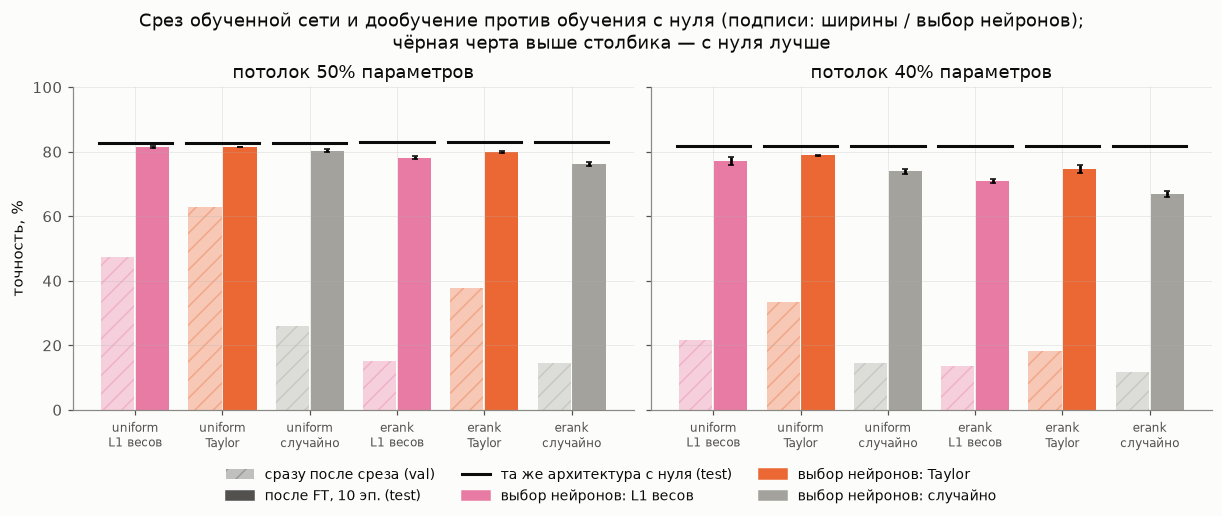

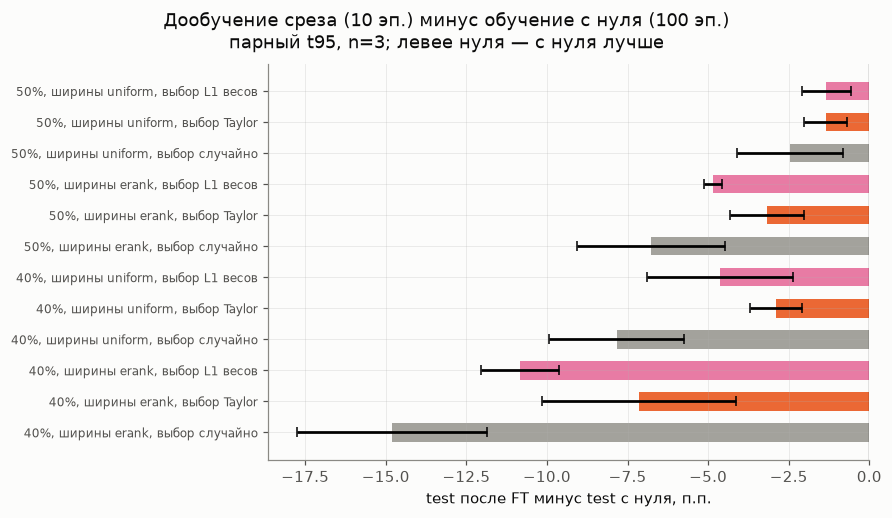

**Вывод.** Срез + FT (10 эп. дообучения против 100 эп. обучения с нуля) хуже обучения с нуля в 36 из 36 пар «сид × потолок × ширины × выбор» (разница от −16,05 до −1,09 п.п.). FT − с нуля при выборе по L1 весов (Li et al., 2017), п.п. [t95]: ширины uniform при 50%: −1,33 [−2,10; −0,57] (n=3); ширины erank при 50%: −4,85 [−5,14; −4,57] (n=3); ширины uniform при 40%: −4,62 [−6,88; −2,36] (n=3); ширины erank при 40%: −10,84 [−12,06; −9,62] (n=3). При выборе по Taylor: ширины uniform при 50%: −1,36 [−2,02; −0,70] (n=3); ширины erank при 50%: −3,17 [−4,31; −2,04] (n=3); ширины uniform при 40%: −2,90 [−3,71; −2,09] (n=3); ширины erank при 40%: −7,15 [−10,16; −4,14] (n=3). Сразу после среза лучше всех сохраняет точность выбор «Taylor» (val 38,1% в среднем по потолкам и ширинам).

In [31]:
combos = [(m, s) for m in FT_METHODS for s in FT_SELECTS]
fig, axes = plt.subplots(1, len(BUDGETS), figsize=(11, 4.6), sharey=True, layout="constrained")
for ax, budget in zip(np.atleast_1d(axes), BUDGETS):
    for i, (method, select) in enumerate(combos):
        rows = by(ft, method=method, budget=budget, select=select)
        color = PALETTE[SELECT[select][1]]
        cut, done = 100 * np.mean([r["cut_val"] for r in rows]), 100 * np.mean([r["ft_test"] for r in rows])
        ax.bar(i - 0.2, cut, width=0.38, color=color, alpha=0.35, hatch="//", edgecolor=color, lw=0)
        ax.bar(i + 0.2, done, width=0.38, color=color, yerr=sd([100 * r["ft_test"] for r in rows]), capsize=2)
        ax.plot([i - 0.42, i + 0.42], [100 * np.mean([r["scratch_test"] for r in rows])] * 2, color=INK, lw=2)
    ax.set_xticks(range(len(combos)), [f"{m}\n{SELECT[s][0]}" for m, s in combos], fontsize=8)
    ax.set(title=f"потолок {budget:.0%} параметров", ylim=(0, 100))
np.atleast_1d(axes)[0].set_ylabel("точность, %")
legend = [plt.Rectangle((0, 0), 1, 1, color=PALETTE["uniform"], alpha=0.35, hatch="//", lw=0),
          plt.Rectangle((0, 0), 1, 1, color=PALETTE["uniform"]), plt.Line2D([], [], color=INK, lw=2)]
fig.legend(legend + [plt.Rectangle((0, 0), 1, 1, color=PALETTE[SELECT[s][1]]) for s in FT_SELECTS],
           ["сразу после среза (val)", f"после FT, {FT_EPOCHS} эп. (test)", "та же архитектура с нуля (test)"]
           + [f"выбор нейронов: {SELECT[s][0]}" for s in FT_SELECTS], loc="outside lower center", ncol=3, fontsize=9)
fig.suptitle("Срез обученной сети и дообучение против обучения с нуля (подписи: ширины / выбор нейронов);\n"
             "чёрная черта выше столбика — с нуля лучше")
plt.show()

FT_GAP = {}  # (budget, width rule, selection) -> paired_summary of FT minus scratch, p.p.
labels, colors = [], []
for budget in BUDGETS:
    for method, select in combos:
        rows = by(ft, method=method, budget=budget, select=select)
        FT_GAP[(budget, method, select)] = paired_summary([100 * (r["ft_test"] - r["scratch_test"]) for r in rows])
        labels.append(f"{budget:.0%}, ширины {method}, выбор {SELECT[select][0]}")
        colors.append(PALETTE[SELECT[select][1]])
summaries = list(FT_GAP.values())
fig, ax = plt.subplots(figsize=(8, 4.6), layout="constrained")
y = np.arange(len(labels))
ax.barh(y, [s["mean_pp"] for s in summaries], xerr=[half_ci(s) for s in summaries], color=colors, capsize=3, height=0.6)
ax.axvline(0, color=INK, lw=0.8)
ax.set_yticks(y, labels, fontsize=8)
ax.invert_yaxis()
ax.set(xlabel="test после FT минус test с нуля, п.п.")
fig.suptitle(f"Дообучение среза ({FT_EPOCHS} эп.) минус обучение с нуля ({EPOCHS} эп.)\n"
             f"парный t95, n={len(SEEDS)}; левее нуля — с нуля лучше")
plt.show()


def ft_gap_text(select: str) -> str:
    """FT minus scratch for one selection rule, per budget and width rule, with paired t95."""
    return "; ".join(f"ширины {m} при {b:.0%}: {ci_text(FT_GAP[(b, m, select)])}" for b in BUDGETS for m in FT_METHODS)


diffs = 100 * (ft_df["ft_test"] - ft_df["scratch_test"])
by_select = 100 * ft_df.groupby("select")["cut_val"].mean()
display(Markdown(
    f"**Вывод.** Срез + FT ({FT_EPOCHS} эп. дообучения против {EPOCHS} эп. обучения с нуля) хуже обучения с нуля "
    f"в {(diffs < 0).sum()} из {len(diffs)} пар «сид × потолок × ширины × выбор» (разница от {diffs.min():+.2f} до "
    f"{diffs.max():+.2f} п.п.). FT − с нуля при выборе по L1 весов (Li et al., 2017), п.п. [t95]: {ft_gap_text('l1')}. "
    f"При выборе по Taylor: {ft_gap_text('taylor')}. Сразу после среза лучше всех сохраняет точность выбор "
    f"«{SELECT[by_select.idxmax()][0]}» (val {by_select.max():.1f}% в среднем по потолкам и ширинам)."))

## Шаг 5. Итерации: сходится ли процедура к стабильной архитектуре

**(a)** Протокол основной серии при постоянном потолке 50%: erank сети предыдущего раунда → ширины
(`fit_budget`, не шире 768) → обучение с нуля → erank новой сети. Раунд 1 — erank-сеть шага 3. Мера сходимости —
среднее по блокам |Δширины| / ширина между соседними раундами.
**(b)** Буквально «повторить шаги 2–4» с убывающим бюджетом 50% → 40%: erank дообученной сети предыдущего раунда →
ширины (не шире прежних) → L1-срез этой сети → 10 эпох дообучения; те же ширины обучаются и с нуля.
Порог «ширины стабильны», последнее изменение < 5%, условный.

In [32]:
# (a) fixed budget, every round trained from scratch (main series: step_iterate)
iterate = []
for seed in SEEDS:
    eranks = inner(base_rows[seed]["layers"], "erank_energy")
    for r in range(1, ITER_ROUNDS + 1):
        widths = fit_budget(eranks, int(ITER_BUDGET * FULL_PARAMS), bases[seed])  # caps: the full 768
        row = scratch(widths, seed)  # round 1 = the erank net of step 3
        iterate.append({"seed": seed, "round": r, "widths": widths, "test_acc": row["test_acc"]})
        eranks = inner(row["inner_layers"], "erank_energy")  # the next round uses the new network's erank


def width_change(a, b) -> float:
    """Mean over blocks of |new - old| / old, in %."""
    return 100 * float(np.mean([abs(y - x) / x for x, y in zip(a, b)]))


changes = {r: [width_change(by(iterate, seed=s, round=r - 1)[0]["widths"], by(iterate, seed=s, round=r)[0]["widths"])
               for s in SEEDS] for r in range(2, ITER_ROUNDS + 1)}

# (b) progressive budgets: erank of the previous fine-tuned net -> widths (capped) -> L1 cut of that net -> FT
progressive = []
for seed in SEEDS:
    parent, parent_id, parent_layers = bases[seed], base_id(seed), base_rows[seed]["layers"]
    for r, budget in enumerate(PROGRESSIVE_BUDGETS, 1):
        widths = fit_budget(inner(parent_layers, "erank_energy"), int(budget * FULL_PARAMS), parent)  # caps: parent
        cut = finetune_cut(parent, parent_id, widths, neuron_scores(parent, "l1"), "l1", seed)  # round 1 = step 4
        progressive.append({"seed": seed, "round": r, "budget": budget, "widths": widths, "cut_val": cut["val_acc_before_ft"],
                            "ft_test": cut["test_acc"], "scratch_test": scratch(widths, seed)["test_acc"],
                            "uniform_test": scratch(widths_for("uniform", seed, budget), seed)["test_acc"]})
        if r < len(PROGRESSIVE_BUDGETS):
            parent, parent_id = load_ft(cut), cut["run_id"]
            parent_layers = cached(f"layers|{parent_id}", lambda: {"layers": layer_metrics(parent, data["x_val"])})["layers"]

display(pd.DataFrame([{"раунд": r, "test, %": 100 * np.mean([x["test_acc"] for x in by(iterate, round=r)]),
                       "изменение ширин, %": np.mean(changes[r]) if r > 1 else np.nan} for r in range(1, ITER_ROUNDS + 1)])
        .round(2).set_index("раунд"))
prog_df = pd.DataFrame(progressive)
prog_df = prog_df.assign(раунд=prog_df["round"], потолок=prog_df["budget"].map("{:.0%}".format))
display((100 * prog_df.groupby(["раунд", "потолок"])[["cut_val", "ft_test", "scratch_test", "uniform_test"]].mean())
        .round(2).rename(columns={"cut_val": "val после среза, %", "ft_test": "test после FT, %",
                                  "scratch_test": "test с нуля, %", "uniform_test": "uniform с нуля, %"}))

,"test, %","изменение ширин, %"
раунд,,
1,83.04,NaN
2,82.29,20.17
3,82.86,16.30


,,"val после среза, %","test после FT, %","test с нуля, %","uniform с нуля, %"
раунд,потолок,,,,
1,50%,15.05,78.18,83.04,82.81
2,40%,38.99,76.85,81.43,81.73


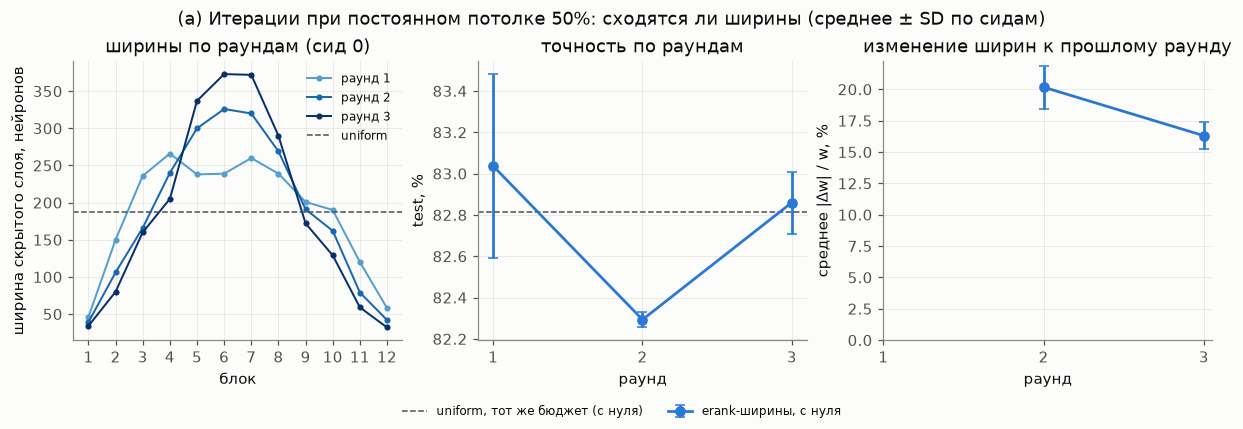

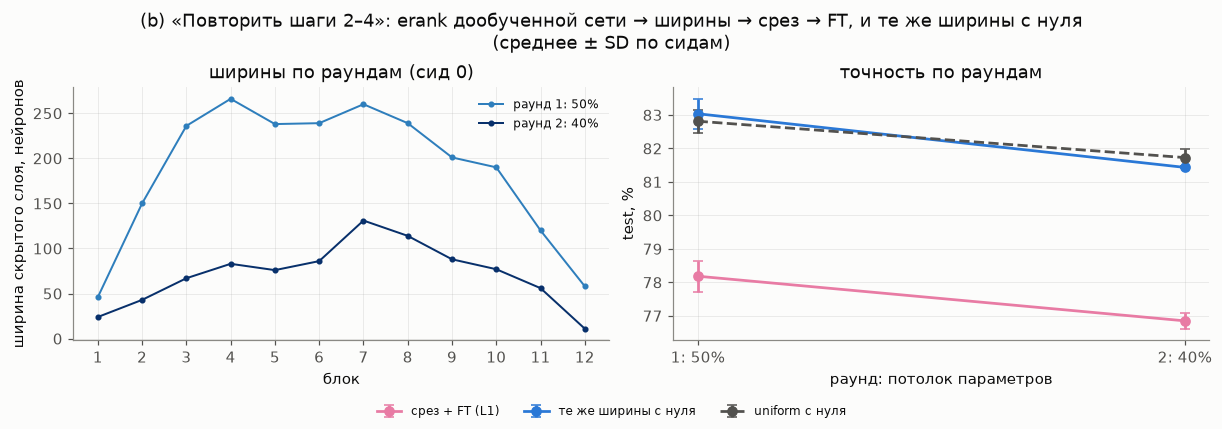

**Вывод.** (a) test по раундам: 83,04 → 82,29 → 82,86% (uniform 82,81%); раунд 3 − раунд 1: −0,18 [−1,51; +1,15] (n=3) п.п.; изменение ширин: 20,2% → 16,3% — стабильной архитектуры за 3 раунда не видно (последнее изменение ≥ 5%; порог условный). (b) последний раунд (40%): срез + FT 76,85%, те же ширины с нуля 81,43%, uniform с нуля 81,73%; срез + FT − с нуля: −4,58 [−5,13; −4,03] (n=3) п.п.

In [33]:
uniform_iter = acc_points(by(alloc, method="uniform", budget=ITER_BUDGET))[0]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8), layout="constrained")
for r in range(1, ITER_ROUNDS + 1):
    axes[0].plot(range(1, 13), by(iterate, seed=S0, round=r)[0]["widths"], color=plt.cm.Blues(0.35 + 0.65 * r / ITER_ROUNDS),
                 marker="o", ms=3, lw=1.3, label=f"раунд {r}")
axes[0].axhline(by(alloc, method="uniform", budget=ITER_BUDGET, seed=S0)[0]["widths"][0], color=PALETTE["uniform"],
                ls="--", lw=1, label="uniform")
axes[0].set(title=f"ширины по раундам (сид {S0})", xlabel="блок", ylabel="ширина скрытого слоя, нейронов",
            xticks=range(1, 13))
axes[0].legend(fontsize=8)
rounds = list(range(1, ITER_ROUNDS + 1))
accs = [acc_points(by(iterate, round=r)) for r in rounds]
axes[1].errorbar(rounds, [a for a, _ in accs], yerr=[e for _, e in accs], color=PALETTE["erank"], marker="o", capsize=3,
                 label="erank-ширины, с нуля")
axes[1].axhline(uniform_iter, color=PALETTE["uniform"], ls="--", lw=1, label="uniform, тот же бюджет (с нуля)")
axes[1].set(title="точность по раундам", xlabel="раунд", ylabel="test, %", xticks=rounds)
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=2, fontsize=8)  # below: no overlap
if ITER_ROUNDS > 1:
    axes[2].errorbar(rounds[1:], [np.mean(changes[r]) for r in rounds[1:]], yerr=[sd(changes[r]) for r in rounds[1:]],
                     color=PALETTE["erank"], marker="o", capsize=3)
axes[2].set(title="изменение ширин к прошлому раунду", xlabel="раунд", ylabel="среднее |Δw| / w, %", xticks=rounds,
            ylim=(0, None))
fig.suptitle(f"(a) Итерации при постоянном потолке {ITER_BUDGET:.0%}: сходятся ли ширины (среднее ± SD по сидам)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
for r, budget in enumerate(PROGRESSIVE_BUDGETS, 1):
    axes[0].plot(range(1, 13), by(progressive, seed=S0, round=r)[0]["widths"], color=plt.cm.Blues(0.4 + 0.6 * r / len(PROGRESSIVE_BUDGETS)),
                 marker="o", ms=3, lw=1.3, label=f"раунд {r}: {budget:.0%}")
axes[0].set(title=f"ширины по раундам (сид {S0})", xlabel="блок", ylabel="ширина скрытого слоя, нейронов",
            xticks=range(1, 13))
axes[0].legend(fontsize=8)
rounds = list(range(1, len(PROGRESSIVE_BUDGETS) + 1))
for key, label, color, ls in [("ft_test", "срез + FT (L1)", PALETTE["l1"], "-"), ("scratch_test", "те же ширины с нуля", PALETTE["erank"], "-"),
                              ("uniform_test", "uniform с нуля", PALETTE["uniform"], "--")]:
    pts = [acc_points(by(progressive, round=r), key) for r in rounds]
    axes[1].errorbar(rounds, [a for a, _ in pts], yerr=[e for _, e in pts], color=color, ls=ls, marker="o", capsize=3,
                     label=label)
axes[1].set_xticks(rounds, [f"{r}: {b:.0%}" for r, b in zip(rounds, PROGRESSIVE_BUDGETS)])
axes[1].set(title="точность по раундам", xlabel="раунд: потолок параметров", ylabel="test, %")
fig.legend(*axes[1].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=8)  # below: no overlap
fig.suptitle("(b) «Повторить шаги 2–4»: erank дообученной сети → ширины → срез → FT, и те же ширины с нуля\n"
             "(среднее ± SD по сидам)")
plt.show()

last = np.mean(changes[ITER_ROUNDS]) if ITER_ROUNDS > 1 else float("nan")
stable = ("ширины близки к стабильным (последнее изменение < 5%; порог условный)" if last < 5 else
          f"стабильной архитектуры за {ITER_ROUNDS} раунда не видно (последнее изменение ≥ 5%; порог условный)")
iter_gain = paired_summary([100 * (by(iterate, seed=s, round=ITER_ROUNDS)[0]["test_acc"]
                                   - by(iterate, seed=s, round=1)[0]["test_acc"]) for s in SEEDS])
prog_last = by(progressive, round=len(PROGRESSIVE_BUDGETS))
prog_gap = paired_summary([100 * (r["ft_test"] - r["scratch_test"]) for r in prog_last])
display(Markdown(
    f"**Вывод.** (a) test по раундам: " + " → ".join(f"{a:.2f}" for a, _ in accs) + f"% (uniform {uniform_iter:.2f}%); "
    f"раунд {ITER_ROUNDS} − раунд 1: {ci_text(iter_gain)} п.п.; изменение ширин: "
    + " → ".join(f"{np.mean(changes[r]):.1f}%" for r in range(2, ITER_ROUNDS + 1))
    + f" — {stable}. (b) последний раунд ({PROGRESSIVE_BUDGETS[-1]:.0%}): срез + FT "
    f"{acc_points(prog_last, 'ft_test')[0]:.2f}%, те же ширины с нуля {acc_points(prog_last, 'scratch_test')[0]:.2f}%, "
    f"uniform с нуля {acc_points(prog_last, 'uniform_test')[0]:.2f}%; срез + FT − с нуля: {ci_text(prog_gap)} п.п."))

## Размер, MACs и время инференса

Параметры и MACs считаются по модулям (хуки на Linear / Conv2d) плюс произведения внутри внимания. Время — медиана
30 запусков после 5 прогревочных на случайных весах (`latency_ms` основной серии): CPU float32, 4 потока, батч 32 и
батч 1 (100 запусков); GPU bfloat16, батч 512. На GPU сначала один прогревочный круг по всем сетям, затем
3 круга, в каждом все сети замеряются по очереди; время сети — медиана трёх кругов, поэтому кратковременное
замедление GPU не достаётся одной сети целиком. Сети: полная, все архитектуры шага 3 сида 0 и low-rank fc2 с рангом
erank (у PCA и SVD одинаковые размеры слоёв, поэтому время одно, а точность у каждого своя). Точность — среднее по
сидам на тесте. Все замеры — из одной сессии; сеть, чьё время на GPU отличается больше чем на 10% от медианы сетей с
теми же MACs (±1%, группы от 3 сетей), называется в выводе. На CPU каждая сеть замеряется один раз, без кругов:
порядок сетей с почти равными MACs между сессиями меняется, поэтому на CPU осмысленны отношения «полная / сжатая»
и Spearman(MACs, время), а не то, какая из равных по MACs сетей быстрее.

In [34]:
def latency_id(name: str) -> str:
    return f"latency|{name}|r{LAT_REPEATS}"


def latency_rows(builds: dict) -> dict:
    """Main series: step_speed_all. Random weights; GPU bf16 batch 512, CPU fp32 batch 32 and 1, LAT_THREADS threads;
    latency_ms unchanged. NEW for the GPU: one warm-up round over all nets not yet timed, then LAT_GPU_ROUNDS rounds,
    each timing every one of them once; a net's GPU time is the median over the rounds (all rounds are stored), so a
    slow stretch of the session does not fall on one net only. builds: {name: () -> model}; returns {name: row}."""
    todo = {name: build() for name, build in builds.items() if latency_id(name) not in stored_rows()}
    gpu = {name: [] for name in todo}
    threads = torch.get_num_threads()
    torch.set_num_threads(LAT_THREADS)
    try:
        if DEVICE == "cuda" and todo:
            for model in todo.values():  # warm-up round: clocks, kernel selection, allocator
                latency_ms(model.to("cuda"), "cuda", 512, LAT_REPEATS)
            for _ in range(LAT_GPU_ROUNDS):
                for name, model in todo.items():
                    gpu[name].append(latency_ms(model, "cuda", 512, LAT_REPEATS))

        def fn(name: str) -> dict:
            model = todo[name].cpu()
            row = {"name": name, "params": count_params(model), "macs": count_macs(model)}
            if gpu[name]:
                row["gpu_ms_b512"], row["gpu_ms_b512_rounds"] = float(np.median(gpu[name])), gpu[name]
            row["cpu_ms_b32"] = latency_ms(model, "cpu", 32, LAT_REPEATS)
            row["cpu_ms_b1"] = latency_ms(model, "cpu", 1, LAT_REPEATS_B1)
            return row

        return {name: cached(latency_id(name), lambda name=name: fn(name)) for name in builds}
    finally:
        torch.set_num_threads(threads)


builds = {"full": lambda: ViT()}
alloc_names = {}
for budget in BUDGETS:
    for method in ALLOC_METHODS:
        w = by(alloc, method=method, budget=budget, seed=S0)[0]["widths"]
        alloc_names[(method, budget)] = f"{method}|{budget}|w={w}"
        builds[alloc_names[(method, budget)]] = lambda w=w: ViT(w)
ranks1 = by(lowrank, mult=1, seed=S0, basis="svd")[0]["ranks"]
builds[f"lowrank|1|ranks={ranks1}"] = lambda: lowrank_fc2(bases[S0], ranks1, "svd", None, None, None)
lat = latency_rows(builds)
speed = [{**lat["full"], "label": "полная", "acc": full_acc}]
for (method, budget), name in alloc_names.items():
    speed.append({**lat[name], "method": method, "budget": budget, "label": f"{METHOD[method][0]}, {budget:.0%}",
                  "acc": acc_points(by(alloc, method=method, budget=budget))[0]})
lat_low = lat[f"lowrank|1|ranks={ranks1}"]
for basis in ["pca", "svd"]:  # same layer shapes, so one timing; each basis keeps its own accuracy
    speed.append({**lat_low, "basis": basis, "label": f"low-rank fc2 ({BASIS[basis][0]}), ранг = erank, после FT",
                  "acc": acc_points(by(lowrank, mult=1, basis=basis))[0]})
speed_df = pd.DataFrame(speed)
cols = ["params", "macs", "cpu_ms_b32", "cpu_ms_b1"] + (["gpu_ms_b512"] if "gpu_ms_b512" in speed_df else [])
display(speed_df.set_index("label")[cols + ["acc"]].round(2)
        .rename(columns={"params": "параметры", "macs": "MACs", "cpu_ms_b32": "CPU батч 32, мс", "cpu_ms_b1": "CPU батч 1, мс",
                         "gpu_ms_b512": "GPU батч 512, мс", "acc": "test, % (среднее по сидам)"}))

,параметры,MACs,"CPU батч 32, мс","CPU батч 1, мс","GPU батч 512, мс","test, % (среднее по сидам)"
label,,,,,,
полная,5362378,359204736,97.76,3.90,13.84,83.39
"uniform (равномерно), 50%",2678158,187860864,55.41,3.60,10.89,82.81
"случайные ширины, 50%",2673538,187565952,55.88,3.66,10.75,83.08
"erank, 50%",2677773,187836288,57.84,3.12,10.84,83.04
"Taylor (глобально), 50%",2680853,188032896,59.19,3.33,10.75,83.17
"L1-потребность блока, 50%",2680853,188032896,60.80,3.42,10.78,83.10
"uniform (равномерно), 40%",2142238,153651072,46.44,3.29,10.27,81.73
"случайные ширины, 40%",2144933,153823104,44.77,3.30,10.17,81.99
"erank, 40%",2143393,153724800,48.92,3.00,10.15,81.79


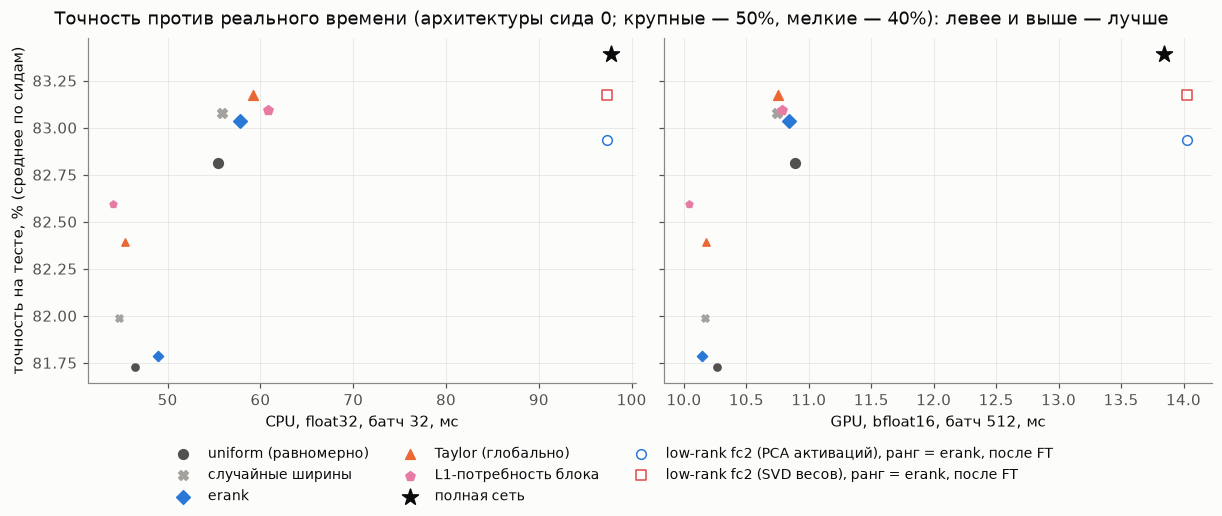

**Вывод.** Spearman(MACs, задержка) по 12 архитектурам: CPU батч 32 +0,89, CPU батч 1 +0,77, GPU батч 512 +0,86. При равных MACs (50%) время на CPU (батч 32) различается до 10% (в этом замере быстрее всех — uniform (равномерно), 50%, медленнее — L1-потребность блока, 50%; при одном замере на CPU такой порядок между сессиями не сохраняется); полная сеть — 97,8 мс. Время на GPU ни у одной сети не отличается больше чем на 10% от медианы сетей с теми же MACs (±1%). Разброс 3 кругов замера GPU у одной сети (max − min от медианы) — меньше 1%.

In [35]:
timings = [("cpu_ms_b32", "CPU, float32, батч 32, мс")] + ([("gpu_ms_b512", "GPU, bfloat16, батч 512, мс")]
                                                          if "gpu_ms_b512" in speed_df else [])
fig, axes = plt.subplots(1, len(timings), figsize=(11 if len(timings) > 1 else 6, 4.6), sharey=True,
                         layout="constrained")
for ax, (key, label) in zip(np.atleast_1d(axes), timings):
    for row in speed:
        if "method" in row:
            st = mstyle(row["method"])
            ax.scatter(row[key], row["acc"], color=st["color"], marker=st["marker"], s=40 if row["budget"] == BUDGETS[0] else 22,
                       label=st["label"] if row["budget"] == BUDGETS[0] else None)
    ax.scatter(speed[0][key], speed[0]["acc"], color=FULL_COLOR, marker="*", s=120, label="полная сеть")
    for row in speed:
        if "basis" in row:
            ax.scatter(row[key], row["acc"], color=PALETTE[row["basis"]], marker=MARKERS[row["basis"]],
                       facecolors="white", s=40, label=row["label"])
    ax.set(xlabel=label)
np.atleast_1d(axes)[0].set_ylabel("точность на тесте, % (среднее по сидам)")
fig.legend(*np.atleast_1d(axes)[0].get_legend_handles_labels(), loc="outside lower center", ncol=3, fontsize=9)
fig.suptitle(f"Точность против реального времени (архитектуры сида {S0}; крупные — {BUDGETS[0]:.0%}, мелкие — "
             f"{BUDGETS[-1]:.0%}): левее и выше — лучше")
plt.show()

timing_names = {"cpu_ms_b32": "CPU батч 32", "cpu_ms_b1": "CPU батч 1", "gpu_ms_b512": "GPU батч 512"}
uniq = speed_df.drop_duplicates("run_id")  # the PCA and SVD low-rank nets share one timed architecture
rho_lat = {key: spearman(uniq["macs"], uniq[key]) for key in timing_names if key in uniq}
same = speed_df[speed_df["budget"] == BUDGETS[0]]
spread = 100 * (same["cpu_ms_b32"].max() / same["cpu_ms_b32"].min() - 1)
slowest, fastest = same.loc[same["cpu_ms_b32"].idxmax(), "label"], same.loc[same["cpu_ms_b32"].idxmin(), "label"]
gpu_text = ""
if "gpu_ms_b512" in uniq:  # NEW: GPU times far from nets with the same MACs are named, rho is given without them
    timed = [r for r in uniq.to_dict("records") if np.isfinite(r["gpu_ms_b512"])]
    flagged = timing_outliers(timed, "gpu_ms_b512")
    if flagged:
        clean = [r for r in timed if all(r["run_id"] != f["run_id"] for f, _ in flagged)]
        gpu_text = (" Время на GPU отличается больше чем на 10% от медианы сетей с теми же MACs (±1%): "
                    + "; ".join(f"{r['label']} — {r['gpu_ms_b512']:.1f} мс при медиане группы {m:.1f} мс "
                                f"({100 * (r['gpu_ms_b512'] / m - 1):+.0f}%)" for r, m in flagged)
                    + f" — возможный выброс замера; без таких точек Spearman(MACs, GPU батч 512) "
                    f"{rho_text(spearman([r['macs'] for r in clean], [r['gpu_ms_b512'] for r in clean]))} "
                    f"по {len(clean)} архитектурам.")
    else:
        gpu_text = (" Время на GPU ни у одной сети не отличается больше чем на 10% от медианы сетей с теми же MACs "
                    "(±1%).")
    rounds = [r["gpu_ms_b512_rounds"] for r in timed if isinstance(r.get("gpu_ms_b512_rounds"), list)
              and len(r["gpu_ms_b512_rounds"]) > 1]
    if rounds:
        worst = max(100 * (max(t) - min(t)) / np.median(t) for t in rounds)
        gpu_text += (f" Разброс {len(rounds[0])} кругов замера GPU у одной сети (max − min от медианы) — "
                     + ("меньше 1%." if worst < 1 else f"до {worst:.0f}%."))
display(Markdown(
    f"**Вывод.** Spearman(MACs, задержка) по {len(uniq)} архитектурам: "
    + ", ".join(f"{timing_names[k]} {rho_text(v)}" for k, v in rho_lat.items())
    + f". При равных MACs ({BUDGETS[0]:.0%}) время на CPU (батч 32) различается до {spread:.0f}% "
    f"(в этом замере быстрее всех — {fastest}, медленнее — {slowest}; при одном замере на CPU такой порядок между "
    f"сессиями не сохраняется); полная сеть — {speed[0]['cpu_ms_b32']:.1f} мс." + gpu_text))

## Итог

Таблица: точность каждого метода минус uniform на том же сиде и бюджете (обучение с нуля), среднее, SD, парный t95 и число сидов;
под ней — ответ на вопрос для этой модели, собранный из чисел шагов 2–5 этого ноутбука.

In [36]:
summary = []
for budget in BUDGETS:
    u = acc_points(by(alloc, method="uniform", budget=budget))[0]
    for method in [m for m in ALLOC_METHODS if m != "uniform"]:
        d = paired_diffs(alloc, method, budget)
        s = paired_summary(d)
        summary.append({"ресурс": "параметры (равные MACs)", "потолок": f"{budget:.0%}", "метод": METHOD[method][0],
                        "uniform, %": u, "метод, %": acc_points(by(alloc, method=method, budget=budget))[0],
                        "Δ, п.п.": s["mean_pp"], "SD": s["sd_pp"], "t95 от": s["ci95_pp"][0] if s["ci95_pp"] else None,
                        "t95 до": s["ci95_pp"][1] if s["ci95_pp"] else None, "n": s["n"],
                        "лучше uniform, сидов": f"{sum(x > 0 for x in d)}/{len(d)}"})
display(pd.DataFrame(summary).set_index(["ресурс", "потолок", "метод"]).round(2))

erank_s = {b: paired_summary(paired_diffs(alloc, "erank", b)) for b in BUDGETS}


def seed_diffs(a: str, b: str, budget: float) -> list[float]:
    """Method a minus method b at `budget`, trained from scratch, paired by seed, p.p."""
    return [100 * (by(alloc, method=a, budget=budget, seed=s)[0]["test_acc"]
                   - by(alloc, method=b, budget=budget, seed=s)[0]["test_acc"]) for s in SEEDS]


taylor_vs_erank = {b: paired_summary(seed_diffs("taylor_global", "erank", b)) for b in BUDGETS}
display(Markdown(
    f"**Ответ для ViT-Tiny / CIFAR-10 (n={len(SEEDS)}):** {erank_headline(erank_s)}. "
    + "; ".join(ci_verdict(erank_s[b], f"erank − uniform при {b:.0%}") for b in BUDGETS)
    + ". Наибольшее среднее Δ среди методов: " + "; ".join(leader_text(summ, b) for b in BUDGETS)
    + ". Классический критерий против erank, парно по сиду: "
    + "; ".join(ci_verdict(taylor_vs_erank[b], f"Taylor − erank при {b:.0%}") for b in BUDGETS) + ". "
    f"Сжимаемость блока: Spearman erank с L1-потребностью {rho_text(rhos['prune']['erank_energy'])} "
    f"(с PCA-потребностью {rho_text(rhos['pca']['erank_energy'])}), номер блока — {rho_text(rhos['prune']['depth'])}; "
    f"лучшая мера для L1-потребности: {best_measure['prune']}"
    + (f"; потребность — лишь верхняя граница (на наименьшем проверенном k) у {floor_n['prune']} из {n_pairs} пар "
       f"блок × сид при L1 и у {floor_n['pca']} из {n_pairs} при PCA, ρ считается на частично совпадающих значениях"
       if any(floor_n.values()) else "") + ". "
    f"Срез + FT ({FT_EPOCHS} эп. дообучения) против обучения с нуля ({EPOCHS} эп.), выбор по L1 весов, FT − с нуля, "
    f"п.п.: {ft_gap_text('l1')}. Итерации (a): раунд {ITER_ROUNDS} − раунд 1 {ci_text(iter_gain)} п.п., изменение "
    f"ширин в последнем раунде {last:.1f}% (порог стабильности 5% условный). Интервалы — обычный t95 по сидам без "
    f"поправки на множественные сравнения; интервал, накрывающий ноль, не означает эквивалентности."))
if DEVICE == "cuda":
    print(f"пиковая память GPU в этой сессии: {torch.cuda.max_memory_allocated() / 2**30:.1f} ГБ")

uniform, %  метод, %  \
ресурс                  потолок метод                                        
параметры (равные MACs) 50%     случайные ширины           82.81     83.08   
                                erank                      82.81     83.04   
                                Taylor (глобально)         82.81     83.17   
                                L1-потребность блока       82.81     83.10   
                        40%     случайные ширины           81.73     81.99   
                                erank                      81.73     81.79   
                                Taylor (глобально)         81.73     82.39   
                                L1-потребность блока       81.73     82.59   

                                                      Δ, п.п.    SD  t95 от  \
ресурс                  потолок метод                                         
параметры (равные MACs) 50%     случайные ширины         0.27  0.37   -0.65   
                                erank                    0.22  0.11   -0.05   
                                Taylor (глобально)       0.36  0.32   -0.44   
                                L1-потребность блока     0.28  0.35   -0.58   
                        40%     случайные ширины         0.26  0.53   -1.06   
                                erank                    0.06  0.07   -0.12   
                                Taylor (глобально)       0.66  0.18    0.21   
                                L1-потребность блока     0.87  0.67   -0.80   

                                                      t95 до  n  \
ресурс                  потолок метод                             
параметры (равные MACs) 50%     случайные ширины        1.18  3   
                                erank                   0.50  3   
                                Taylor (глобально)      1.16  3   
                                L1-потребность блока    1.14  3   
                        40%     случайные ширины        1.58  3   
                                erank                   0.24  3   
                                Taylor (глобально)      1.12  3   
                                L1-потребность блока    2.53  3   

                                                     лучше uniform, сидов  
ресурс                  потолок метод                                      
параметры (равные MACs) 50%     случайные ширины                      3/3  
                                erank                                 3/3  
                                Taylor (глобально)                    3/3  
                                L1-потребность блока                  2/3  
                        40%     случайные ширины                      2/3  
                                erank                                 2/3  
                                Taylor (глобально)                    3/3  
                                L1-потребность блока                  3/3

**Ответ для ViT-Tiny / CIFAR-10 (n=3):** разница erank − uniform не отличима от нуля при n=3 ни при одном бюджете. erank − uniform при 50%: +0,22 [−0,05; +0,50] (n=3) — разница не отличима от нуля при n=3; erank − uniform при 40%: +0,06 [−0,12; +0,24] (n=3) — разница не отличима от нуля при n=3. Наибольшее среднее Δ среди методов: при 50% — Taylor (глобально) (+0,36 [−0,44; +1,16] (n=3)); при 40% — L1-потребность блока (+0,87 [−0,80; +2,53] (n=3)). Классический критерий против erank, парно по сиду: Taylor − erank при 50%: +0,14 [−0,91; +1,18] (n=3) — разница не отличима от нуля при n=3; Taylor − erank при 40%: +0,60 [+0,10; +1,11] (n=3) — выше нуля. Сжимаемость блока: Spearman erank с L1-потребностью −0,40 (с PCA-потребностью −0,44), номер блока — −0,75; лучшая мера для L1-потребности: нет — ни у одной меры ρ не достигает 0,59 (наибольший +0,17 — 99% энергии); у меры «erank по λ (основной)» знак обратный (ρ = −0,40): блокам с большим erank скорее нужно меньше нейронов; обратный порядок с ρ ≤ −0,59: erank до GELU (fc1) (−0,84), stable rank (−0,63), participation ratio (−0,61); потребность — лишь верхняя граница (на наименьшем проверенном k) у 18 из 36 пар блок × сид при L1 и у 26 из 36 при PCA, ρ считается на частично совпадающих значениях. Срез + FT (10 эп. дообучения) против обучения с нуля (100 эп.), выбор по L1 весов, FT − с нуля, п.п.: ширины uniform при 50%: −1,33 [−2,10; −0,57] (n=3); ширины erank при 50%: −4,85 [−5,14; −4,57] (n=3); ширины uniform при 40%: −4,62 [−6,88; −2,36] (n=3); ширины erank при 40%: −10,84 [−12,06; −9,62] (n=3). Итерации (a): раунд 3 − раунд 1 −0,18 [−1,51; +1,15] (n=3) п.п., изменение ширин в последнем раунде 16,3% (порог стабильности 5% условный). Интервалы — обычный t95 по сидам без поправки на множественные сравнения; интервал, накрывающий ноль, не означает эквивалентности.

пиковая память GPU в этой сессии: 0.8 ГБ


### Сравнение с основной серией

Ориентиры основной серии (тот же рецепт и код, 3 сида; срез и low-rank — 2 сида), числа из её отчёта, не из этого
ноутбука:

- База: test 83,39% (83,22 / 83,35 / 83,61); erank скрытых слоёв 53–312 из 768, максимум в средних блоках.
- Spearman с L1-потребностью: erank −0,398, participation ratio −0,612, erank по σ +0,031, номер блока −0,755;
  точки замера: до GELU −0,836, только дисперсии +0,063. С PCA-потребностью: erank −0,439.
- Обучение с нуля, разница с uniform [t95], n=3: erank +0,22 [−0,05; +0,50] при 50% и +0,06 [−0,12; +0,24] при 40%;
  Taylor +0,36 [−0,44; +1,16] и +0,66 [+0,21; +1,12]; uniform 82,81% и 81,73%.
- Срез + 10 эпох FT всегда хуже обучения с нуля: uniform / L1 при 50% −1,16 п.п., erank / L1 при 50% −4,82 п.п.;
  Taylor-выбор даёт лучшую точность сразу после среза.
- Low-rank fc2 с рангом erank сохраняет около 96% параметров (у большинства блоков fc2 не меняется): PCA
  82,64 → 82,67%, SVD 83,23 → 83,06% до / после FT.
- Итерации при 50%: test 83,04 → 82,29 → 82,86%, ширины меняются на 20% и 16% — стабилизации за 3 раунда нет.